# 计算机网络，从零到能解释、能实验、能排障

### 一本围绕「打开网页时发生了什么」展开的中文实验手册

你在浏览器里输入一个网址。几百毫秒后，页面出现了。在这段时间里，机器可能查询了域名、找到网关、跨越多个网络、建立连接、验证证书，再把字节拼成网页。

本书要把这条路径拆开，让你能回答三个问题：

1. **怎么到达？** 数据如何离开自己的电脑，找到另一台机器？
2. **怎么正确交付？** 丢包、乱序、重复、拥塞发生时，协议怎样协作？
3. **怎么证明？** 看到“打不开”“很慢”“偶尔失败”，怎样用证据定位？

适合刚接触计算机网络的人，也适合会写程序、但对网络只有零散印象的人。先修只需变量、循环、函数和基本字节概念；需要的二进制、单位、概率和操作系统概念会在使用前补齐。

**学习方式：读一段 → 先预测 → 运行一格 → 改一个参数 → 用自己的话解释。** 不需要一次读完，建议每次完成 1–2 章。

> 你提供的 TCP/IP 全景图是很好的“协议很多”的提醒，但里面混合了 OSI、TCP/IP、历史协议和厂商技术。正文以现代互联网核心路径为主；第 21 章专门回看这张图，解释哪些需要纠正、哪些只需认识名字。


## 导航与学习路线

| 章节 | 核心问题 | 动手做什么 |
|---|---|---|
| [00 使用说明](#ch00) | 怎样运行、怎样检验自己？ | 检查环境 |
| [01 网络全景](#ch01) | 包、协议、主机和路由器是什么？ | 跟踪一次访问 |
| [02 分层与封装](#ch02) | 为什么要分层？ | 算协议开销 |
| [03 比特与性能](#ch03) | 100 Mbps 为什么不是 100 MB/s？ | 算时延、带宽时延积 |
| [04 物理层与链路](#ch04) | 电信号怎样变成可检查的帧？ | 检测比特翻转 |
| [05 以太网、交换与 Wi-Fi](#ch05) | 同一个局域网怎样转发？ | 模拟 MAC 学习 |
| [06 IPv4 与子网](#ch06) | 地址和掩码各自表达什么？ | CIDR、VLSM 规划 |
| [07 ARP、DHCP 与网关](#ch07) | 刚连上 Wi-Fi 如何获得网络？ | 判断下一跳 |
| [08 路由与 ICMP](#ch08) | 互联网怎样选路？ | 最长前缀匹配、最短路径 |
| [09 IPv6 与 MTU](#ch09) | 地址更多以后，哪些机制也变了？ | 地址压缩、MSS 估算 |
| [10 端口、UDP 与 NAT](#ch10) | 一台电脑的不同程序如何分流？ | 本机 UDP、NAT 映射 |
| [11 TCP 连接与字节流](#ch11) | 可靠连接为什么仍需要应用协议？ | 本机 TCP 长度前缀协议 |
| [12 可靠传输与流控](#ch12) | 丢包怎样补？慢接收者怎么办？ | ACK、重传与窗口模型 |
| [13 拥塞控制与排队](#ch13) | 为什么越发越慢？ | 画拥塞窗口与缓冲膨胀 |
| [14 DNS](#ch14) | 域名怎样变成地址？ | TTL 缓存、编码查询 |
| [15 HTTP 与浏览器](#ch15) | HTTP 真正在交换什么？ | 本机 HTTP、条件请求 |
| [16 TLS、HTTPS 与 QUIC](#ch16) | 加密连接信任谁？ | 看哈希、HMAC 与握手 |
| [17 Socket 与服务架构](#ch17) | 网络知识怎样落到程序里？ | 超时预算、重试与幂等 |
| [18 安全与边界](#ch18) | 哪些保护解决哪些威胁？ | 建立威胁模型 |
| [19 观测与排障](#ch19) | 如何从现象走到证据？ | 抓包读法、故障树 |
| [20 综合项目与复习](#ch20) | 能否把所有层串起来？ | 诊断报告与学习验收 |
| [21 协议图、术语与资料](#ch21) | 如何继续深入？ | 历史协议、速查与参考 |

**第一遍主线（约 12–18 小时）：** 00–08 → 10–12 → 14–16 → 19–20；先读解释、运行默认实验，跳过扩展问题。

**第二遍工程线（约 8–12 小时）：** 09、13、17、18，重做计算题，修改实验参数，并完成综合项目。时间只是安排建议，不是熟练度保证。

**复习判断：** 能画出路径，能算一题，能解释一项证据。只记住缩写还没有完成这一章。


<a id="ch00"></a>

## 00 · 使用说明与实验约定

**这一章学会：** 启动环境；分清真实实验、简化模型与外部观测。


在本主题目录中运行：

```bash
uv sync --python 3.11.15
uv run jupyter lab
```

在 VS Code 中选择 `computer-network/.venv/bin/python` 作为 Notebook 内核。使用已有 Python 3.10+ 环境时，也可以安装 `jupyterlab matplotlib ipykernel` 后打开本文件。

- **默认完整运行无需访问外网。** 数学与协议模型完全离线；UDP、TCP、HTTP 实验只绑定 `127.0.0.1`，由系统分配空闲端口，并在结束时关闭。安装环境需要下载依赖。
- **默认实验无需管理员权限。** 如果托管 Notebook 禁止本机监听，Socket 实验会报权限错误；在本机 Jupyter 运行即可。
- **蓝图不是抓包。** 标注“模型”的代码用于隔离一个机制，不代表完整操作系统协议栈；真实 Socket 实验则调用系统网络栈。
- **外部命令是选做。** 第 19 章给出 `dig`、`curl`、Wireshark 等观测步骤，不会在“运行全部”时执行。只观察自己的流量或获得授权的环境；抓包可能包含凭据与私人数据。
- **按顺序运行。** 首格准备公共模块，后续少数实验复用先前的函数。重启内核后选择“运行全部”可以得到干净结果。

本书地址使用文档示例网段，例如 `192.0.2.0/24`、`198.51.100.0/24`、`203.0.113.0/24` 和 `2001:db8::/32`，它们不作为真实公网测试目标。


In [1]:
import sys
import math
import json
import struct
import socket
import threading
import ipaddress
from concurrent.futures import ThreadPoolExecutor
from contextlib import contextmanager
from collections import defaultdict
from urllib.parse import urlsplit
import matplotlib.pyplot as plt

assert sys.version_info >= (3, 10), "Please use Python 3.10+"
plt.rcParams.update({"figure.figsize": (8, 3.6), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.2, "figure.dpi": 110})
print("Python:", sys.version.split()[0])
print("Mode: offline models + loopback sockets; no external network requests")


Python: 3.11.15
Mode: offline models + loopback sockets; no external network requests


<a id="ch01"></a>

## 01 · 从一台电脑到整个互联网

**这一章学会：** 区分主机、链路、交换机、路由器和服务；建立端到端路径。


### 1.1 网络解决什么问题

**计算机网络**把能够通信的设备连接起来，让不同进程交换数据。设备是“主机”，传输介质是“链路”，约定数据格式和处理方式的是“协议”。两个程序只有约好“每一段字节是什么意思、下一步该做什么”，通信才有意义。

互联网是**网络的网络**。你家、学校、运营商、云服务商各自管理网络，再通过路由互连。网络边缘运行应用，网络核心转发分组。

- **主机 host：** 手机、电脑、服务器；运行浏览器、聊天程序、数据库等进程。
- **交换机 switch：** 典型二层交换机依据 MAC 地址，在局域网中转发帧。
- **路由器 router：** 根据目的 IP 地址和路由表，在不同网络之间转发包。
- **家庭“路由器”：** 往往同时集成路由、交换、Wi-Fi 接入点、DHCP、NAT 和防火墙。一个盒子可以承担多个角色。
- **服务器：** 一种程序角色，不是一种神奇硬件。你的电脑也能在本机实验里运行 HTTP 服务。

**分组交换**把大消息拆成较小的分组，让多个用户共享链路。遇到繁忙出口，分组先排队；队列装不下时丢弃。由此产生了后面要解决的时延、丢包与拥塞问题。电路交换则为会话预留资源，适合用来对比“共享与保证”的代价。




回程可能走不同路径。CDN 可以在较近节点返回内容，因此浏览器实际连接的未必是源站。


### 1.2 先看全程，再逐章展开

假设打开 `https://www.example.com/guide?q=network`，典型冷启动流程如下：

1. 解析 URL，确定协议、主机名、端口与资源路径。
2. 从本地缓存或 DNS 获得地址；代理、浏览器 DNS 策略会改变具体查询位置。
3. 查路由表，选择网卡与下一跳；在本地链路上解析下一跳的链路层地址。
4. 与远端建立传输连接：HTTP/1.1、HTTP/2 常用 TCP；HTTP/3 使用 QUIC over UDP。
5. 为 HTTPS 建立安全上下文，验证服务身份。
6. 发送 HTTP 请求，收到状态、响应头和响应体。
7. 浏览器解析 HTML、CSS、JavaScript，可能发起更多请求并渲染。

这不是每次都从头执行的固定串行剧本：DNS 缓存、连接复用、并行请求、Service Worker、代理与预连接都会改变步骤。先理解冷启动，再讨论优化。


In [2]:
u = urlsplit("https://www.example.com:8443/guide?q=network#tcp")
request_target = u.path + ("?" + u.query if u.query else "")
print("scheme:", u.scheme, "host:", u.hostname, "port:", u.port)
print("HTTP request target:", request_target)
print("fragment stays in browser:", u.fragment)
assert "#" not in request_target


scheme: https host: www.example.com port: 8443
HTTP request target: /guide?q=network
fragment stays in browser: tcp


### 停下来想一想

家里的 Wi-Fi 已连接，但网页打不开，能否证明“互联网已经连通”？URL 中的 `#tcp` 会作为 HTTP 请求目标发送吗？

<details>
<summary>展开参考答案（先尝试再看）</summary>

不能。Wi-Fi 连接只说明本地无线接入的部分条件成立，仍可能没有有效 IP、默认路由、DNS 或远端可达性。片段标识 `#tcp` 留给客户端定位资源中的位置，不包含在 HTTP 请求目标里。

</details>


<a id="ch02"></a>

## 02 · 分层、封装与协议边界

**这一章学会：** 把七层模型映射到常用协议栈；解释封装与逐跳变化。


### 2.1 用分层控制复杂度

浏览器希望“把这些数据交给对方”，不想自己处理无线电调制。网卡希望“发送这个帧”，不需要理解网页。每层为上层提供服务，同时与对端同层遵循协议。

| OSI 七层 | 教学用五层 | 核心职责 | 常见例子 |
|---|---|---|---|
| 7 应用、6 表示、5 会话 | 应用层 | 应用语义、编码、会话与安全机制 | HTTP、DNS、SMTP；TLS 常位于应用与传输之间 |
| 4 传输 | 传输层 | 进程间通信、复用，按协议提供可靠性等 | TCP、UDP；QUIC 在 UDP 上实现传输功能 |
| 3 网络 | 网络层 | 跨网络寻址与转发 | IPv4、IPv6、ICMP |
| 2 数据链路 | 链路层 | 同一链路上的帧与介质访问 | Ethernet、802.11 Wi-Fi |
| 1 物理 | 物理层 | 比特对应的物理信号 | 铜缆、光纤、无线物理层 |

TCP/IP 也常写成四层：把物理层和链路层合并为网络接入层。**模型的作用是帮助分析，不是把所有现实技术硬塞进唯一格子。** ARP 处于 IP 与链路寻址的接口，TLS 和 QUIC 也体现出工程边界与教科书层次并非一一对应。

### 2.2 封装：同一份数据，逐层加上说明

HTTP 数据交给 TCP，TCP 添加端口、序号等首部；IP 再添加源地址、目的地址等；以太网添加 MAC 首部和帧校验尾部。接收方逐层解析并交给正确对象。

```text
应用消息                 [ HTTP 数据                         ]
TCP 段          [ TCP头  | HTTP 数据                         ]
IP 包   [ IP头 | TCP头  | HTTP 数据                         ]
链路帧 [ MAC头 | IP头 | TCP头 | HTTP 数据                 | FCS ]
物理层  以电压、光脉冲或无线信号传输编码后的比特
```

一个 HTTP 消息可能跨多个 TCP 段；一次 `send()` 也不决定一个数据包的边界。分层封装示意的是逻辑关系，不是承诺一条消息恰好对应一个包。

### 2.3 哪些信息逐跳改变

路由器收到帧后取出 IP 包，查路由表，再为下一条链路构造新帧。**MAC 地址通常随链路改变，目的 IP 在无 NAT、隧道或代理改写的普通转发中保持不变。** IPv4 TTL 逐跳减小，首部校验和随之更新；IPv6 对应 Hop Limit。

交换机在同一二层域内转发时，通常不替换原帧的源、目的 MAC。中间设备既可以做纯转发，也可以做 NAT、代理、隧道，因此排障时必须辨认实际角色。


In [3]:
# Model: one 1000-byte application payload; IPv4/TCP without options or TLS.
payload, tcp_header, ip_header, ethernet_header, fcs = 1000, 20, 20, 14, 4
frame_bytes = payload + tcp_header + ip_header + ethernet_header + fcs
wire_byte_times = frame_bytes + 8 + 12  # preamble/SFD + inter-frame gap time
print("Frame bytes:", frame_bytes)
print("Application fraction of frame:", f"{payload / frame_bytes:.2%}")
print("Application fraction of wire byte-times:", f"{payload / wire_byte_times:.2%}")
assert frame_bytes == 1058


Frame bytes: 1058
Application fraction of frame: 94.52%
Application fraction of wire byte-times: 92.76%


**读结果：** 帧长度是 1058 字节，线上还要计入前导码和帧间间隔占用的时间。间隔不是帧内数据。本例不含 VLAN、TCP 选项、TLS、确认包或重传；真实有效吞吐量会受这些因素影响。

**改一改：** 把 `payload` 改为 100、1400，比较比例。若改到很小，还需要补上以太网最小帧带来的填充；若超过路径 MTU，则不能继续假设它只占一个包。


### 停下来想一想

同一电脑给远方网站发数据，以太网目的 MAC 应该写网站网卡的 MAC，还是本地网关的 MAC？

<details>
<summary>展开参考答案（先尝试再看）</summary>

目的 IP 是远端服务器地址；如果路由判断远端不在本地链路，帧的目的 MAC 是本地下一跳网关的 MAC。ARP 不会跨互联网搜索网站网卡。

</details>


<a id="ch03"></a>

## 03 · 单位、时延、吞吐量与带宽时延积

**这一章学会：** 进行单位换算；区分传输、传播、排队和处理时延。


### 3.1 不混用三个量

- **带宽 bandwidth：** 链路理论传输能力，常用 bit/s，例如 100 Mbps = $100\times10^6$ bit/s。
- **吞吐量 throughput：** 实际单位时间传输的数据量；必须说明测的是链路、传输还是应用层。
- **有效吞吐量 goodput：** 单位时间真正交付的应用有效数据，不计重传与协议开销。

1 Byte = 8 bit。MB 通常是 $10^6$ 字节，MiB 是 $2^{20}$ 字节。100 Mbps 理想上限是 12.5 MB/s，不能直接理解成 100 MB/s。

### 3.2 一个包为什么需要时间

$$d_{total}=d_{processing}+d_{queue}+d_{transmission}+d_{propagation}$$

- **发送/传输时延** $L/R$：把 $L$ 比特推出速率为 $R$ 的接口，需要多久。
- **传播时延** $D/v$：信号穿过距离 $D$，传播速度为 $v$，需要多久。
- **排队时延**：前面的包还没走完，你的包先等着。负载变化会使它剧烈波动。
- **处理时延**：设备检查、查表或执行其他处理所需时间。

光纤中传播速度可粗取 $2\times10^8$ m/s。提升带宽可以缩短发送时延，却不会让光在同一根光纤里传播得更快。RTT 是往返时间，不必恰好等于单向时延的两倍，因为路径和排队可能不对称。

### 3.3 让链路装满需要多少在途数据

**带宽时延积 BDP** 是 $R\times RTT$，表示要持续利用链路，大约需允许多少比特在确认返回前处于途中。一个忽略丢包和开销的上界是：

$$throughput \le \min(R_{bottleneck},\ W/RTT)$$

其中 $W$ 是有效在途窗口（比特）。高带宽、高时延链路可能需要很大窗口，单纯加快网卡无法解决窗口太小的问题。


In [4]:
rate_bps = 100_000_000
packet_bytes = 1500
distance_m = 1_000_000
speed_mps = 200_000_000
rtt_s = 0.050
window_bytes = 64 * 1024
print("Serialization (ms):", packet_bytes * 8 / rate_bps * 1000)
print("Propagation one-way (ms):", distance_m / speed_mps * 1000)
print("BDP (bytes):", rate_bps * rtt_s / 8)
print("64 KiB window ceiling (Mbps):", window_bytes * 8 / rtt_s / 1e6)
print("100 MiB ideal transfer (s):", 100 * 2**20 * 8 / rate_bps)
assert math.isclose(rate_bps * rtt_s / 8, 625_000)


Serialization (ms): 0.12000000000000001
Propagation one-way (ms): 5.0
BDP (bytes): 625000.0
64 KiB window ceiling (Mbps): 10.48576
100 MiB ideal transfer (s): 8.388608


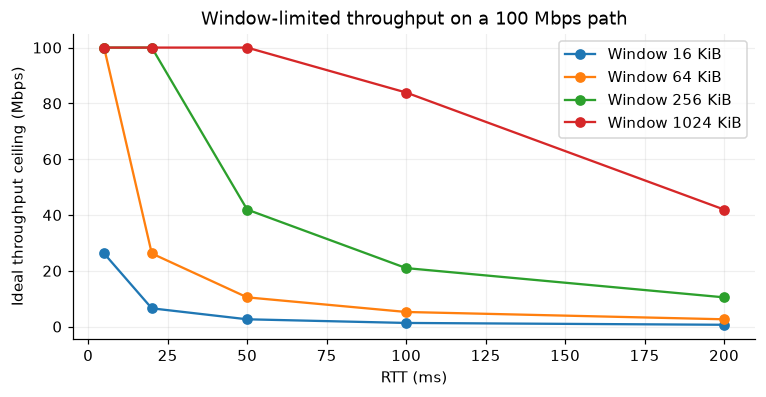

In [5]:
rtts_ms = [5, 20, 50, 100, 200]
for window_kib in [16, 64, 256, 1024]:
    ceilings = [min(rate_bps, window_kib * 1024 * 8 / (r / 1000)) / 1e6
                for r in rtts_ms]
    plt.plot(rtts_ms, ceilings, marker="o", label=f"Window {window_kib} KiB")
plt.xlabel("RTT (ms)")
plt.ylabel("Ideal throughput ceiling (Mbps)")
plt.title("Window-limited throughput on a 100 Mbps path")
plt.legend()
plt.show()


**看图：** 窗口固定时，RTT 越大，吞吐上限越低；窗口足够大后，瓶颈转为链路速率。图中是理论上界，不是测速结果。

**扩展计算：** 两条 100 Mbps 链路串联，中间设备完整接收一个 1500 字节包后再转发，即存储转发。忽略传播、处理和排队，首包至少需要两次 0.12 ms；大量包则可流水传输，稳态吞吐并不会因此减半。


### 停下来想一想

1 Gbps、RTT 80 ms 的路径，BDP 是多少字节？如果只允许 1 MB 在途，理想吞吐上限是多少？

<details>
<summary>展开参考答案（先尝试再看）</summary>

BDP = 10⁹ × 0.08 / 8 = 10,000,000 字节，即 10 MB。1 MB 窗口给出的上限是 1,000,000 × 8 / 0.08 = 100 Mbps；它比链路带宽低十倍。

</details>


<a id="ch04"></a>

## 04 · 物理链路：信号、帧与差错检测

**这一章学会：** 理解信号与比特的关系；区分检测错误、纠正错误和安全认证。


一根线或一段无线频谱传的是物理信号。发送方编码、调制，接收方根据电压、相位、频率或光信号恢复比特。噪声、衰减、干扰和同步偏差都可能导致错误。

**链路层帧**给连续比特加上边界、地址和校验信息。以太网的 FCS 使用 CRC 检测许多常见错误，通常在发现错误后丢弃帧。检测不等于纠错：某些链路使用前向纠错 FEC，Wi-Fi 还使用链路级确认与重传；端到端 TCP 仍然需要自己的可靠性机制，因为路径中的其他地方也会丢包。

### 4.1 从奇偶校验理解“冗余”

最简单的偶校验增加一位，使 1 的总数为偶数。接收者发现奇数个 1，就知道发生过错误。但两个比特同时翻转可能保持奇偶性，因此它检测不出所有错误。

CRC 把比特串看作多项式，通过约定的生成多项式求余数。它是高效差错检测，不是加密，也不能证明发送者身份。攻击者可以修改数据并重新计算 CRC。

**吞吐受什么约束？** 除了设备速率，还受信道带宽、噪声和编码方案限制。理想高斯噪声信道容量公式 $C=B\log_2(1+S/N)$ 中，$B$ 是 Hz，$S/N$ 是线性功率比；若给的是 dB，要先用 $10^{dB/10}$ 转换。这里的“信道带宽 Hz”和接口“数据率 bit/s”不能混用。


In [6]:
def even_parity(bits):
    return sum(bits) % 2

bits = [1, 0, 1, 1, 0, 0, 1, 0]
parity = even_parity(bits)
one_error = bits.copy()
one_error[2] ^= 1
two_errors = bits.copy()
two_errors[2] ^= 1
two_errors[5] ^= 1
print("Original valid:", (sum(bits) + parity) % 2 == 0)
print("One flipped bit detected:", (sum(one_error) + parity) % 2 != 0)
print("Two flipped bits detected:", (sum(two_errors) + parity) % 2 != 0)
assert (sum(one_error) + parity) % 2 == 1
assert (sum(two_errors) + parity) % 2 == 0
bandwidth_hz, snr_db = 20e6, 20
print("Ideal Shannon capacity (Mbps):",
      round(bandwidth_hz * math.log2(1 + 10 ** (snr_db / 10)) / 1e6, 2))


Original valid: True
One flipped bit detected: True
Two flipped bits detected: False
Ideal Shannon capacity (Mbps): 133.16


### 停下来想一想

链路已经有 CRC，为什么 TCP 仍要处理丢失？CRC 能防止恶意篡改吗？

<details>
<summary>展开参考答案（先尝试再看）</summary>

CRC 能帮助发现传输错误，但帧可能被丢弃，路由器队列也可能溢出；链路检测不保证端到端交付。CRC 没有密钥，攻击者可以重新计算，不能用来认证来源或抵御主动篡改。

</details>


<a id="ch05"></a>

## 05 · 以太网、交换机、VLAN 与 Wi-Fi

**这一章学会：** 跟踪二层转发；理解广播域和无线共享介质。


### 5.1 交换机怎样认识设备

MAC 地址标识链路层接口，常见形式为 48 位，例如 `02:00:00:00:00:0a`。它与 IP 的作用不同：IP 用于跨网络寻址，MAC 用于当前链路交付。MAC 可以被软件修改，移动设备还会使用随机化地址，不能当成不可伪造的全球身份证。

交换机的学习流程：

1. 帧从端口进入，记录“**源 MAC → 入端口**”。
2. 如果目的 MAC 已知且位于另一个端口，只向该端口转发。
3. 如果目的未知，向同 VLAN 内除入端口外的端口泛洪；广播也这样传播。
4. 如果目的就在入端口，不需要转发到其他端口。表项会老化，也会随着设备移动而更新。

为什么从源地址学？因为交换机知道这个帧实际从哪条链路进来，而目的地址并不能告诉它对方在哪里。

### 5.2 广播域、环路与 VLAN

二层广播在广播域内传播，路由器通常隔开广播域。VLAN 在同一物理交换基础设施上划分逻辑广播域；802.1Q 标签常用于交换机间传送多个 VLAN。跨 VLAN 通信需要三层转发。

以太网帧没有 IP 那样的 TTL。交换环路可能让广播持续复制，形成广播风暴。STP/RSTP 等机制通过控制活动拓扑避免环路。VLAN 是隔离工具，但完整安全边界还需要正确的路由、访问控制和管理配置。

### 5.3 Wi-Fi 不是“无线版独占网线”

同频道附近设备共享无线介质，通常使用 CSMA/CA、随机退避和链路确认协调访问。干扰、距离、隐藏节点、频道拥挤都会影响吞吐与时延。信号强只说明部分无线条件，不能证明上网快。

现代交换式全双工以太网基本不靠 CSMA/CD 竞争介质；不要把早期共享以太网的碰撞机制照搬到今天。Wi-Fi 连接认证、获得 IP、DNS 可用和互联网可达是不同阶段。


In [7]:
# Model: one VLAN, three ports, no aging or loops.
mac_table = {}
ports = {1, 2, 3}

def switch_frame(src, dst, incoming):
    mac_table[src] = incoming
    if dst not in mac_table:
        outgoing = sorted(ports - {incoming})
    elif mac_table[dst] == incoming:
        outgoing = []
    else:
        outgoing = [mac_table[dst]]
    return outgoing

assert switch_frame("A", "B", 1) == [2, 3]
assert switch_frame("B", "A", 2) == [1]
assert switch_frame("A", "B", 1) == [2]
assert switch_frame("C", "A", 1) == []
print("Learned table:", mac_table)
print("First A -> B: flood; reply B -> A: unicast; next A -> B: unicast")


Learned table: {'A': 1, 'B': 2, 'C': 1}
First A -> B: flood; reply B -> A: unicast; next A -> B: unicast


### 停下来想一想

电脑 A、B 在不同 VLAN，但接在同一台交换机上，能仅凭二层交换直接互通吗？交换机首次收到 A 发往 B 的帧，会从目的地址学到 B 的位置吗？

<details>
<summary>展开参考答案（先尝试再看）</summary>

不同 VLAN 是不同广播域，需要三层路由和相应访问策略才能互通。交换机从源地址学习 A 的位置；只有看到 B 发出的帧等信息后，才会建立 B 的位置映射。

</details>


<a id="ch06"></a>

## 06 · IPv4、CIDR 与子网规划

**这一章学会：** 用二进制解释掩码；完成地址范围与 VLSM 规划。


### 6.1 地址 = 网络前缀 + 其余位

IPv4 地址由 32 位组成，通常写成四个十进制数。`192.168.10.34/27` 中，`/27` 表示前 27 位是网络前缀，剩余 5 位在该子网内区分地址。

子网掩码 `/27 = 255.255.255.224`。对 IP 和掩码进行按位与，就得到网络地址。最后一个字节中，32 个地址为一组，因此 `.34` 属于 `.32–.63`。

- 网络地址：`192.168.10.32`
- 广播地址：`192.168.10.63`
- 普通广播子网可用主机地址：`.33–.62`，共 30 个

常见公式 $2^{32-p}-2$ 适用于通常保留网络和广播地址的 IPv4 子网。**/31 点到点链路可使用两个地址，/32 表示单个地址或主机路由**，不要机械减二。

### 6.2 常用范围

| 范围 | 用途 | 容易混淆的地方 |
|---|---|---|
| `10.0.0.0/8` | 私有地址 | 不在公网全球路由，但可在私网间被路由 |
| `172.16.0.0/12` | 私有地址 | 不是所有 `172.*` 都是私网 |
| `192.168.0.0/16` | 私有地址 | 家庭网常见，跨站点可能发生重叠 |
| `127.0.0.0/8` | 回环 | `127.0.0.1` 指向本机，不是邻居电脑 |
| `169.254.0.0/16` | IPv4 链路本地 | 常在未获取正常配置时出现，不能据此断定唯一原因 |
| `100.64.0.0/10` | 运营商共享地址 | 常见于 CGNAT，不属于 RFC 1918 私网三段 |
| `0.0.0.0` | 依上下文表示未指定等 | 服务绑定它通常表示所有本机 IPv4 接口 |
| `0.0.0.0/0` | 默认路由前缀 | 是路由范围，不是可分配主机地址 |

IP 地址通常配置在网络接口上，一台机器可以有多张网卡、多个 IP。DHCP 动态分配使地址随时间变化。


In [8]:
iface = ipaddress.ip_interface("192.168.10.34/27")
net = iface.network
print("IP bits:  ", f"{int(iface.ip):032b}")
print("Mask bits:", f"{int(net.netmask):032b}")
print("Network:", net, "Mask:", net.netmask)
print("Broadcast:", net.broadcast_address)
print("Usable:", net.network_address + 1, "to", net.broadcast_address - 1)
print("Usable count:", net.num_addresses - 2)
assert str(net.network_address) == "192.168.10.32"
assert iface.ip in net
assert ipaddress.ip_address("192.168.10.70") not in net
print("/31 hosts:", list(ipaddress.ip_network("192.0.2.0/31").hosts()))


IP bits:   11000000101010000000101000100010
Mask bits: 11111111111111111111111111100000
Network: 192.168.10.32/27 Mask: 255.255.255.224
Broadcast: 192.168.10.63
Usable: 192.168.10.33 to 192.168.10.62
Usable count: 30
/31 hosts: [IPv4Address('192.0.2.0'), IPv4Address('192.0.2.1')]


### 6.3 VLSM：按需求分配，而不是每组都给 /24

有一个 `192.168.50.0/24`，三个团队需要 50、25、10 个主机地址（需求已含网关等接口）。先给最大的需求分配：50 → `/26`（62 可用），25 → `/27`（30 可用），10 → `/28`（14 可用）。

关键不仅是“数量够”，还要让网络地址位于正确边界，且网段互不重叠。`.64/26` 是合法网络起点，`.70/26` 不是；后者是这个网络里的一个地址。


In [9]:
allocations = [
    ("Team A", 50, ipaddress.ip_network("192.168.50.0/26")),
    ("Team B", 25, ipaddress.ip_network("192.168.50.64/27")),
    ("Team C", 10, ipaddress.ip_network("192.168.50.96/28")),
]
parent = ipaddress.ip_network("192.168.50.0/24")
for name, demand, subnet in allocations:
    assert subnet.subnet_of(parent)
    assert subnet.num_addresses - 2 >= demand
    print(name, subnet, "usable:", subnet.num_addresses - 2,
          "range:", subnet.network_address + 1, "-", subnet.broadcast_address - 1)
for i, (_, _, a) in enumerate(allocations):
    for _, _, b in allocations[i + 1:]:
        assert not a.overlaps(b)


Team A 192.168.50.0/26 usable: 62 range: 192.168.50.1 - 192.168.50.62
Team B 192.168.50.64/27 usable: 30 range: 192.168.50.65 - 192.168.50.94
Team C 192.168.50.96/28 usable: 14 range: 192.168.50.97 - 192.168.50.110


### 停下来想一想

`192.168.1.130/26` 的网络地址、广播地址和通常可用数量是什么？`172.32.1.1` 是 RFC 1918 私有地址吗？

<details>
<summary>展开参考答案（先尝试再看）</summary>

/26 每块 64 个地址，所以网络是 192.168.1.128/26，广播是 .191，可用 .129–.190，共 62 个。172.32.1.1 不在 172.16.0.0–172.31.255.255 中，不属于 RFC 1918 私有范围。

</details>


<a id="ch07"></a>

## 07 · ARP、DHCP 与默认网关

**这一章学会：** 解释新设备入网与跨网段首包；区分 DNS 解析和地址解析。


### 7.1 DHCP：先拿到配置

常见 IPv4 DHCP 初始流程记作 DORA：Discover → Offer → Request → ACK。客户端在尚无可用地址时，可从 `0.0.0.0:68` 向广播地址的服务器端口 67 发起请求。DHCP 提供租约、地址、掩码、网关、DNS 等参数；续租时不一定重走完整广播流程，DHCP Relay 可以把请求转交到其他网络中的服务器。

**网关与 DNS 不一定是同一设备。** 网关帮你转发跨网段数据，DNS 帮你查询名称。家用路由器可能同时提供两种服务，只是产品集成。

### 7.2 ARP：把当前链路上的下一跳 IPv4 映射到 MAC

假设本机是 `192.168.1.10/24`，网关是 `192.168.1.1`。

- 目标 `192.168.1.20`：路由判断它在本地，ARP 查询它的 MAC，直接交付。
- 目标 `203.0.113.80`：路由选网关，ARP 查询 **192.168.1.1** 的 MAC，将目的 IP 仍为远端的包交给网关。

ARP 请求通常广播：“谁拥有这个 IPv4 地址？”拥有者通常单播回复自己的 MAC。邻居缓存减少重复查询；缓存会过期。ARP 没有内建强身份认证，错误或恶意响应可能污染缓存。

IPv6 使用基于 ICMPv6 的邻居发现 NDP，不使用 ARP。




“默认网关”是在没有更具体匹配路由时使用的下一跳，而不是每个包必经的特殊服务器。


In [10]:
local_net = ipaddress.ip_network("192.168.1.0/24")
gateway = ipaddress.ip_address("192.168.1.1")

def next_hop_simple(destination):
    target = ipaddress.ip_address(destination)
    return target if target in local_net else gateway

for target in ["192.168.1.20", "203.0.113.80"]:
    print("destination:", target, "ARP target:", next_hop_simple(target))
assert str(next_hop_simple("203.0.113.80")) == "192.168.1.1"


destination: 192.168.1.20 ARP target: 192.168.1.20
destination: 203.0.113.80 ARP target: 192.168.1.1


**模型边界：** 这里只演示“一个直连网段 + 一个默认网关”；真实系统会查完整路由表，VPN、策略路由和多网卡可能改变下一跳。下一章补上最长前缀匹配。

**一个常见故障：** 本机掩码误设为 `/16`，远端实际上在另一个 `/24`。主机可能误以为目标直连，持续 ARP 而不是把包交给网关。知道 IP 不等于知道应该走哪条链路。


### 停下来想一想

DNS 已返回正确的远端 IP，但网关 ARP 查询一直没有回应。此时反复更换 DNS 能解决核心问题吗？

<details>
<summary>展开参考答案（先尝试再看）</summary>

不能。名称已经解析，当前失败点是本地下一跳的链路交付。应检查网卡状态、VLAN、网关地址、掩码、邻居可达性和链路配置。

</details>


<a id="ch08"></a>

## 08 · IP 转发、路由协议与 ICMP

**这一章学会：** 执行最长前缀匹配；区分路由与转发；理解 ping/traceroute 的证据边界。


### 8.1 转发是逐包动作，路由是生成路径知识

**数据平面**按已有表项转发包；**控制平面**通过静态配置、路由协议等建立和更新表项。路由器不必在每个包到来时重新搜索整个互联网。

最核心的查表规则是**最长前缀匹配**：匹配目的地址的候选路由里，前缀最长的最具体。例如 `10.1.2.3` 同时匹配 `/8`、`/16` 和 `/24`，优先 `/24`。只有前缀相同时，协议优先级、度量、策略、ECMP 等才进一步决定路径；它们不能取代最长前缀规则。

- **静态路由：** 管理员显式配置，简单可控，拓扑变化时通常需要人工或其他机制处理。
- **OSPF/IS-IS：** 典型域内链路状态协议，传播拓扑信息并计算路径。
- **RIP：** 距离向量协议，适合认识收敛、环路和计数到无穷等问题，现代大型网络较少以它为主。
- **BGP：** 在自治系统 AS 之间交换可达性，路径选择深受运营策略影响，不是简单选物理最短或时延最低的路径。

**收敛**指拓扑改变后，设备逐步得到一致可用的转发状态。收敛期间可能短暂丢包或环路。


In [11]:
routes = [
    (ipaddress.ip_network("0.0.0.0/0"), "default gateway"),
    (ipaddress.ip_network("10.0.0.0/8"), "corporate WAN"),
    (ipaddress.ip_network("10.1.0.0/16"), "campus"),
    (ipaddress.ip_network("10.1.2.0/24"), "lab VLAN"),
    (ipaddress.ip_network("10.1.2.9/32"), "specific host tunnel"),
]
def lookup_route(address):
    ip = ipaddress.ip_address(address)
    matches = [(net, hop) for net, hop in routes if ip in net]
    return max(matches, key=lambda entry: entry[0].prefixlen) if matches else None

for address in ["10.1.2.9", "10.1.2.8", "10.1.7.3", "203.0.113.8"]:
    print(address, "->", lookup_route(address))
assert lookup_route("10.1.2.9")[0].prefixlen == 32
assert lookup_route("10.1.2.8")[0].prefixlen == 24


10.1.2.9 -> (IPv4Network('10.1.2.9/32'), 'specific host tunnel')
10.1.2.8 -> (IPv4Network('10.1.2.0/24'), 'lab VLAN')
10.1.7.3 -> (IPv4Network('10.1.0.0/16'), 'campus')
203.0.113.8 -> (IPv4Network('0.0.0.0/0'), 'default gateway')


In [12]:
# A link-state shortest-path model, not a full OSPF implementation.
import heapq

graph = {
    "A": {"B": 2, "C": 8},
    "B": {"A": 2, "C": 1, "D": 5},
    "C": {"A": 8, "B": 1, "D": 2},
    "D": {"B": 5, "C": 2},
}
def shortest_path(graph, start, goal):
    frontier = [(0, start, [start])]
    visited = set()
    while frontier:
        cost, node, path = heapq.heappop(frontier)
        if node in visited:
            continue
        visited.add(node)
        if node == goal:
            return cost, path
        for neighbor, weight in graph[node].items():
            if neighbor not in visited:
                heapq.heappush(frontier, (cost + weight, neighbor, path + [neighbor]))
    return math.inf, []

cost, path = shortest_path(graph, "A", "D")
print("Minimum additive cost:", cost, "path:", " -> ".join(path))
assert (cost, path) == (5, ["A", "B", "C", "D"])


Minimum additive cost: 5 path: A -> B -> C -> D


### 8.2 ICMP：网络的错误与诊断信号

ICMP 携带 Echo Request/Reply、目的不可达、TTL 超时等控制信息。它直接承载在 IP 中，不使用 TCP/UDP 端口。

- `ping` 常利用 ICMP Echo 测试可达性和 RTT。没有响应可能是过滤、限速或回程问题，不能单独证明目标离线。
- `traceroute` 逐步增大 TTL/Hop Limit，利用中间路由器的超时回应暴露部分路径。探测可以使用 UDP、ICMP 或 TCP，取决于工具和选项。
- 某一跳显示 `*` 只说明这次探测没有收到期望回复。若后续跳和终点正常，不能把这一跳判定为“完全不转发”。
- 路由器回复控制报文可能限速，显示出的 RTT 也不等于该链路自身的单向时延；多路径与回程不对称会进一步影响解释。


### 停下来想一想

10.1.2.9 同时匹配 `/24` 路由（metric 1）和 `/32` 路由（metric 100），该选哪个？traceroute 第三跳不回应、终点却回应，能说第三跳断网吗？

<details>
<summary>展开参考答案（先尝试再看）</summary>

选 /32，因为更具体的前缀优先；metric 不能覆盖这个规则。不能说第三跳断网，它可能仍在正常转发，只是不回复或限速回复探测。

</details>


<a id="ch09"></a>

## 09 · IPv6、分片、MTU 与 MSS

**这一章学会：** 解释 IPv6 的机制变化；识别“小包通、大包不通”的原因。


### 9.1 IPv6 不只是更长的 IPv4

IPv6 使用 128 位地址，以十六进制分组表示。每组可省略前导零；连续全零组可以用一次 `::` 压缩。`2001:db8::1` 是文档示例地址；`::1` 是回环地址；`fe80::/10` 是链路本地范围，实际使用链路本地地址时常需接口作用域，例如 `%en0`。

IPv6 基本首部固定 40 字节，无 IPv4 式首部校验和。IPv6 没有广播，使用多播等机制；NDP 基于 ICMPv6 进行邻居发现、路由器发现和相关操作。

主机可通过 **RA（路由器通告）**获知默认路由和前缀，通过 **SLAAC** 形成地址；也可使用 DHCPv6 获取地址或其他配置。常见部署中默认路由来自 RA，不应套用 IPv4 DHCP 的所有细节。双栈允许 IPv4、IPv6 并存；客户端可能用 Happy Eyeballs 等策略减少某一地址族故障带来的等待。

### 9.2 MTU 决定一跳能装下多大的 IP 包

以太网常见 IP MTU 是 1500 字节。隧道增加外层首部，通常压缩可用的内层 MTU。**路径 MTU** 是整条路径各链路 MTU 的最小值。

- IPv4 在允许时可由路由器分片；设置 DF 后，装不下的包通常被丢弃并触发需要分片的 ICMP 信息。
- IPv6 路由器不做分片；发送端根据路径信息调整，必要时由发送端使用分片扩展首部。
- 路径 MTU 发现依赖反馈或基于探测的机制。错误屏蔽必要的 ICMP/ICMPv6 可能造成黑洞：连接和小请求成功，大数据传输卡住。

TCP **MSS** 是单段 TCP 数据大小的协商上限，不包含 TCP/IP 首部。常见无选项估算：IPv4 为 1500−20−20=1460，IPv6 为 1500−40−20=1440；实际选项、扩展首部和路径条件会影响发送的数据大小。MSS 不等于应用消息长度，也不能假定所有网络都是 1500 MTU。


In [13]:
v6 = ipaddress.ip_address("2001:0db8:0000:0000:0000:0000:0000:0001")
print("Compressed:", v6.compressed)
print("Expanded:", v6.exploded)
print("IPv6 address bits:", v6.max_prefixlen)
for mtu in [1500, 1400, 1280]:
    print("MTU", mtu, "IPv4 TCP payload ceiling", mtu - 20 - 20,
          "IPv6 TCP payload ceiling", mtu - 40 - 20)
assert v6.compressed == "2001:db8::1"


Compressed: 2001:db8::1
Expanded: 2001:0db8:0000:0000:0000:0000:0000:0001
IPv6 address bits: 128
MTU 1500 IPv4 TCP payload ceiling 1460 IPv6 TCP payload ceiling 1440
MTU 1400 IPv4 TCP payload ceiling 1360 IPv6 TCP payload ceiling 1340
MTU 1280 IPv4 TCP payload ceiling 1240 IPv6 TCP payload ceiling 1220


### 停下来想一想

TCP 三次握手成功，但较大响应一直重传；禁用 VPN 后恢复，最值得检验的一个假设是什么？IPv6 路由器会替你分片吗？

<details>
<summary>展开参考答案（先尝试再看）</summary>

检查 VPN 隧道引入的 MTU 缩小、MSS 与路径 MTU 发现是否正常，以及必要的 ICMP 反馈是否被过滤。IPv6 中间路由器不会替发送端分片，会通过 Packet Too Big 等反馈让发送端调整。这个现象是线索，还需抓包与对照测试验证。

</details>


<a id="ch10"></a>

## 10 · 端口、UDP 与 NAT

**这一章学会：** 用端点区分进程；理解数据报边界和地址转换。


### 10.1 IP 找接口，端口帮助分流到进程

端口是传输层中的 16 位编号，范围 0–65535。TCP 端口和 UDP 端口处于不同命名空间。操作系统根据协议、地址、端口及 Socket 状态等信息分发数据。

一条 TCP 连接通常用源 IP、源端口、目的 IP、目的端口四元组标识；加上协议成为常见的五元组描述。服务器同一个监听端口可以接受许多客户端连接，因为它们的远端端点不同。

| 常见默认端口 | 协议与用途 | 理解要点 |
|---|---|---|
| TCP 22 | SSH | 加密远程登录，替代很多 Telnet 使用场景 |
| TCP 80 / 443 | HTTP / HTTPS（常见 TCP 场景） | 端口只是默认约定，不能单靠端口证明内容 |
| UDP 443 | QUIC / HTTP/3 常用 | 传输可靠性由 QUIC 提供 |
| UDP/TCP 53 | DNS | 两种都重要；TCP 不只用于区域传送 |
| UDP 67/68 | DHCPv4 | 服务器/客户端端口 |
| UDP 123 | NTP | 时钟同步 |
| TCP 25 / 587 / 993 | SMTP 中继 / 邮件提交 / IMAPS | 邮件发送与收取是不同协议角色 |

客户端通常使用临时端口，具体范围由系统决定。实验中 `bind(("127.0.0.1", 0))` 让系统选择空闲端口；这里的 0 是分配请求。

### 10.2 UDP：保留消息边界，其他由应用决定

UDP 首部仅 8 字节，携带源端口、目的端口、长度和校验和。它保留数据报边界，但不提供内建确认、重传、排序、流控或拥塞控制。丢失、重复、乱序都需要应用根据语义处理。UDP 不会自动比 TCP “更快”，性能取决于协议设计与场景。

实时语音可能宁可丢掉过时数据；DNS 适合小请求响应；QUIC 则在 UDP 上实现可靠流、加密和拥塞控制。IPv4 UDP 校验和可以省略，IPv6 中通常要求使用（存在受限例外）；本书实验交给系统实现。

### 实验：用真实 UDP Socket 交换两个数据报

先预测：发送 `one` 和 `two`，接收者会看到一条六字节消息吗？下面只在本机回环通信；它能展示 API 的数据报边界，不能模拟公网丢包率。


In [14]:
with socket.socket(socket.AF_INET, socket.SOCK_DGRAM) as udp_server,      socket.socket(socket.AF_INET, socket.SOCK_DGRAM) as udp_client:
    udp_server.bind(("127.0.0.1", 0))
    udp_server.settimeout(2)
    udp_client.settimeout(2)
    endpoint = udp_server.getsockname()
    received = []
    for message in [b"one", b"two"]:
        udp_client.sendto(message, endpoint)
        data, peer = udp_server.recvfrom(1024)
        received.append(data)
        udp_server.sendto(b"ack:" + data, peer)
        reply, _ = udp_client.recvfrom(1024)
        print("datagram:", data, "reply:", reply)
    assert received == [b"one", b"two"]


datagram: b'one' reply: b'ack:one'
datagram: b'two' reply: b'ack:two'


**观察：** 每次接收拿到一个数据报。若接收缓冲区小于数据报长度，可能发生截断，某些平台 API 会报告相应错误；不能像 TCP 那样指望下一次 `recvfrom()` 自动取回剩余部分。

### 10.3 NAT/PAT：在边界改写地址与端口

家庭网络中，多台主机可通过一个公网 IPv4 地址出站。NAT 设备维护映射，例如：

```text
TCP 192.168.1.10:51000 -> 203.0.113.9:40001 -> 198.51.100.20:443
TCP 192.168.1.11:51000 -> 203.0.113.9:40002 -> 198.51.100.20:443
```

回包到达不同外部端口，再被映射回各自内部主机。具体映射键、端点相关性、过滤规则和超时因实现而异；这是一个简化 PAT 例子。

NAT 不等于防火墙，更不等于加密。家用设备的状态防火墙常与 NAT 一起工作；无法直接接受入站连接通常涉及映射和过滤。P2P 会使用 STUN/TURN/ICE 等机制探测、协调或中继连接；端口映射也可能受上游 CGNAT 限制。


In [15]:
# Model: one remote destination, endpoint-independent style mapping for this example.
public_ip = "203.0.113.9"
nat_table = {}
for internal, public_port in [(('192.168.1.10', 51000), 40001),
                              (('192.168.1.11', 51000), 40002)]:
    nat_table[("TCP", public_ip, public_port)] = internal
print("Reply to public port 40002 ->", nat_table[("TCP", public_ip, 40002)])
assert nat_table[("TCP", public_ip, 40001)] != nat_table[("TCP", public_ip, 40002)]


Reply to public port 40002 -> ('192.168.1.11', 51000)


### 停下来想一想

两个程序都使用“端口 53”，一定冲突吗？NAT 能证明数据已加密吗？

<details>
<summary>展开参考答案（先尝试再看）</summary>

不一定：还要看 TCP/UDP、绑定地址、地址族和 Socket 选项等。TCP 53 与 UDP 53 可同时存在。NAT 只涉及地址转换及相关状态，不证明载荷加密。

</details>


<a id="ch11"></a>

## 11 · TCP：连接、序号与字节流

**这一章学会：** 解释三次握手、关闭与 TIME_WAIT；写出有消息边界的 TCP 程序。


### 11.1 TCP 向应用提供什么

TCP 提供面向连接、全双工、可靠、有序的**字节流**。丢失的段可能被重传，接收端按序向应用交付字节。可靠性不意味着永远不会失败：如果连接无法继续，应用仍要处理超时、错误和中断；“对方 TCP 已确认”也不等于“对方业务已成功入库”。

TCP 首部至少 20 字节，包括端口、序号、确认号、标志、窗口和校验和等。序号针对字节，SYN 与 FIN 各占用一个序号；纯 ACK 不占序号。

### 11.2 三次握手为什么有三步

```text
客户端                                      服务器
CLOSED                                      LISTEN
  | ---- SYN, seq=1000 --------------------> | SYN-RECEIVED
  | <--- SYN+ACK, seq=5000, ack=1001 -------- |
  | ---- ACK, seq=1001, ack=5001 ----------> | ESTABLISHED
ESTABLISHED
```

两个方向有独立的初始序号空间。握手交换序号和选项，并使双方获得对方能接收自己数据的证据。第三步让服务器知道它的 SYN 已被确认，并有助于处理历史重复请求。不要把它简化为“为了确保网络绝对可靠”。实际抓包工具经常显示从 0 开始的**相对序号**，不代表真实初始序号总是 0。

### 11.3 关闭是两个方向分别结束

一方发送 FIN 表示“我不再发送新数据”，仍可接收另一方向的数据，因此可以半关闭。常见关闭图有四个报文，但 ACK 和 FIN 可以合并，不能机械要求每次都恰好四个包。RST 则表示复位/异常终止的一类情况。

主动关闭方通常经历 TIME_WAIT，让旧连接的延迟报文过期，并能重发最后的 ACK。它通常持续 2MSL，具体时长由实现决定；并不是“所有关闭都由客户端进入 TIME_WAIT”。

### 11.4 最重要的编程事实：`send()` 的边界不会被保留

发送方两次 `send(b"abc")`、`send(b"def")`，接收方可能按 `ab`、`cdef` 读到，也可能一次读到全部。TCP 不会替应用区分两条业务消息。常见应用分帧方式有固定长度、分隔符、长度前缀；这里实现 **4 字节大端长度 + 消息体**。

大端/网络字节序表示高位字节在前。文本需要先编码成字节，接收完整消息后再解码，不能随意按 TCP 读取块切开 UTF-8 字符。


In [16]:
MAX_MESSAGE_BYTES = 1_000_000

def recv_exact(sock, size):
    chunks = bytearray()
    while len(chunks) < size:
        part = sock.recv(size - len(chunks))
        if not part:
            raise EOFError(f"Peer closed: wanted {size}, received {len(chunks)}")
        chunks.extend(part)
    return bytes(chunks)

def pack_message(payload):
    if len(payload) > MAX_MESSAGE_BYTES:
        raise ValueError("Message exceeds lab limit")
    return struct.pack("!I", len(payload)) + payload

def recv_message(sock):
    size = struct.unpack("!I", recv_exact(sock, 4))[0]
    if size > MAX_MESSAGE_BYTES:
        raise ValueError("Message exceeds lab limit")
    return recv_exact(sock, size)

class ChunkReader:
    """A deterministic receive model; each recv returns at most a tiny chunk."""
    def __init__(self, payload, chunk_size=2):
        self.payload = payload
        self.chunk_size = chunk_size
    def recv(self, n):
        size = min(n, self.chunk_size, len(self.payload))
        part, self.payload = self.payload[:size], self.payload[size:]
        return part

fake = ChunkReader(pack_message(b"abc") + pack_message(b"def"))
assert recv_message(fake) == b"abc"
assert recv_message(fake) == b"def"
assert recv_message(ChunkReader(pack_message(b""))) == b""
for malformed, expected in [(b"\x00\x00", EOFError),
                            (struct.pack("!I", MAX_MESSAGE_BYTES + 1), ValueError),
                            (struct.pack("!I", 5) + b"ab", EOFError)]:
    try:
        recv_message(ChunkReader(malformed))
    except expected:
        pass
    else:
        raise AssertionError("Malformed input was not rejected")
print("Framing tests passed: split reads, two messages, empty body, truncated and oversized input")


Framing tests passed: split reads, two messages, empty body, truncated and oversized input


In [17]:
def serve_two_messages(listener):
    conn, _ = listener.accept()
    with conn:
        conn.settimeout(3)
        messages = [recv_message(conn), recv_message(conn)]
        conn.sendall(pack_message(b" | ".join(messages)))
        return messages

with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as listener:
    listener.bind(("127.0.0.1", 0))
    listener.listen(1)
    listener.settimeout(3)
    with ThreadPoolExecutor(max_workers=1) as pool:
        task = pool.submit(serve_two_messages, listener)
        with socket.create_connection(listener.getsockname(), timeout=3) as client:
            # Combine two application messages in one write to test framing.
            client.sendall(pack_message(b"hello") + pack_message(b"network"))
            reply = recv_message(client)
        received = task.result(timeout=4)
print("Server decoded:", received)
print("Client decoded:", reply)
assert received == [b"hello", b"network"]
assert reply == b"hello | network"


Server decoded: [b'hello', b'network']
Client decoded: b'hello | network'


**读结果：** 服务器恢复了两个应用消息，即使它们被合并在一次写入中。真实回环读取如何分块由系统决定，因此上一格的 `ChunkReader` 专门、确定性地覆盖短读取情况。

**为什么要限制长度？** 若客户端在首部声明几 TB，服务端不能无限分配或等待。这里限制消息大小并设置 Socket 超时；生产程序还需要总截止时间、并发限额、认证和日志。

**动手扩展：** 把一个消息换成 `"你好，网络".encode("utf-8")`，在拿到完整消息后解码；再尝试发送空消息。不要把 `recv()` 返回 `b""`（对端有序关闭的信号）与长度前缀为 0 的合法应用消息混淆。


### 停下来想一想

客户端发送 100 字节，服务器 TCP 回 ACK 后立即崩溃。能否断言订单已创建？一次 `recv(4096)` 是否保证获得完整 JSON？

<details>
<summary>展开参考答案（先尝试再看）</summary>

不能。TCP ACK 只说明相应字节已被接收端 TCP 接收，不证明业务处理或持久化完成。recv 返回当前可读的部分字节，JSON 必须由长度、分隔或明确协议状态确定边界。

</details>


<a id="ch12"></a>

## 12 · 可靠传输、累计 ACK 与流量控制

**这一章学会：** 追踪字节序号；区分接收窗口和拥塞窗口。


### 12.1 从停等到滑动窗口

最简单的可靠传输是：发送一份数据 → 等确认 → 超时则重传。若发一个包只需 0.1 ms，往返却需 50 ms，绝大部分时间都在等。**滑动窗口**允许在确认回来之前发送多个段，把链路流水线填起来。

可靠传输需要处理三种模糊情况：数据丢了、ACK 丢了、数据只是迟到了。序号帮助识别重复与位置，定时器让发送者在收不到反馈时重试；重传可能产生重复，所以接收方也要去重。

### 12.2 ACK 表示“接下来期望哪个字节”

假设已经收到字节 1000–1999，那么累计 ACK=2000。若 2000–2999 丢失、3000–3999 先到，累计 ACK 仍为 2000。接收端可以缓存乱序数据，并用 SACK 告知已收到的范围，减少不必要的重传。缺口补齐后，ACK 可以一次前移到 4000。

经典 TCP 会使用重复 ACK、重传超时等信号；现代实现还可能采用更复杂的丢失检测算法。RTO 会根据 RTT 估计与变化调整，重传后一般退避。随意固定一个很短的超时，会把正常延迟误当丢包。

### 12.3 两个窗口保护不同对象

- **接收窗口 rwnd：** 接收端还有多少缓冲空间，避免快发送者压垮慢接收者。
- **拥塞窗口 cwnd：** 发送端对网络可承受在途量的约束，避免压垮中间网络。

允许在途字节数大致受 `min(rwnd, cwnd)` 限制；新增可发送量还要扣除已在途字节，并受应用供给、MSS、发送节奏等条件影响。接收窗口为零时，TCP 有窗口探测等机制，避免窗口更新丢失后永久僵持。


In [18]:
# Model: fixed-size 1000-byte segments, unlimited reordering buffer, no wraparound.
expected_seq = 1000
segment_size = 1000
buffered = set()
acks = []
for seq in [1000, 3000, 3000, 2000]:
    if seq >= expected_seq:
        buffered.add(seq)
    while expected_seq in buffered:
        buffered.remove(expected_seq)
        expected_seq += segment_size
    acks.append(expected_seq)
    print("received seq:", seq, "ACK:", expected_seq, "buffer:", sorted(buffered))
assert acks == [2000, 2000, 2000, 4000]

rwnd, cwnd, in_flight = 64_000, 20_000, 12_000
print("Can send new bytes:", max(0, min(rwnd, cwnd) - in_flight))
assert min(rwnd, cwnd) - in_flight == 8000


received seq: 1000 ACK: 2000 buffer: []
received seq: 3000 ACK: 2000 buffer: [3000]
received seq: 3000 ACK: 2000 buffer: [3000]
received seq: 2000 ACK: 4000 buffer: []
Can send new bytes: 8000


In [19]:
# Stop-and-wait model with a scripted first loss; retransmission succeeds.
payload = b"important bytes"
delivered = set()
application_deliveries = []
attempts = 0
for event in ["data lost", "ack lost", "success"]:
    attempts += 1
    if event == "data lost":
        print("attempt", attempts, ": no delivery, timeout")
        continue
    if 0 not in delivered:
        delivered.add(0)
        application_deliveries.append(payload)
    if event == "ack lost":
        print("attempt", attempts, ": delivered, ACK lost, timeout")
    else:
        print("attempt", attempts, ": duplicate suppressed, ACK received")
assert application_deliveries == [payload]
assert attempts == 3


attempt 1 : no delivery, timeout
attempt 2 : delivered, ACK lost, timeout
attempt 3 : duplicate suppressed, ACK received


**模型说明：** 第一格模拟累计确认和去重，未实现真实 TCP 的重叠段、序号回绕、定时器与有限缓冲；第二格刻意安排“数据丢失、ACK 丢失、重传成功”，展示为何可靠传输必须同时有重传和去重。它们不是对本机丢包的测量。

**改一改：** 将到达序列改成 `[3000, 2000, 1000]`，先写下三个 ACK 再运行。仅最后一次到达才能让连续前缀向前移动。


### 停下来想一想

rwnd=32 KB、cwnd=12 KB、在途数据=10 KB，忽略其他限制还可以发送多少？累计 ACK=9000 是“第 9000 个包”吗？

<details>
<summary>展开参考答案（先尝试再看）</summary>

还可发送 min(32,12)−10=2 KB，单位需保持一致。ACK=9000 表示当前序号空间里接下来期望的字节位置，而非第 9000 个包。

</details>


<a id="ch13"></a>

## 13 · 拥塞控制、排队与缓冲膨胀

**这一章学会：** 解释慢启动、拥塞避免和排队延迟；避免把模型误认为真实算法。


### 13.1 网络也会被压垮

接收方很快，不代表中间瓶颈链路很快。如果多个发送者持续以高于出口的总速率发包，队列就增长，随后丢包。发送者全部立即重传还可能加重拥塞。

经典 TCP 教学模型包含：

1. **慢启动：** cwnd 从较小值开始，收到确认后增长；在简化的每 RTT 视角下近似指数增长。
2. **拥塞避免：** 到达阈值后近似每 RTT 线性增长。
3. **拥塞反馈：** 丢失或 ECN 标记促使算法调整速率。ECN 允许网络在丢包前显式标记拥塞，需端到端支持。
4. **恢复：** 快速重传、快速恢复与超时恢复的行为不相同，不能都画成完全一样的窗口折半。

真实系统可能使用 CUBIC、BBR 等算法，窗口增长、信号选择和恢复细节不同。下面画的是 **AIMD 教学曲线**，用于理解“逐步试探、拥塞后收缩”，不是 Linux 某个内核版本的测量。


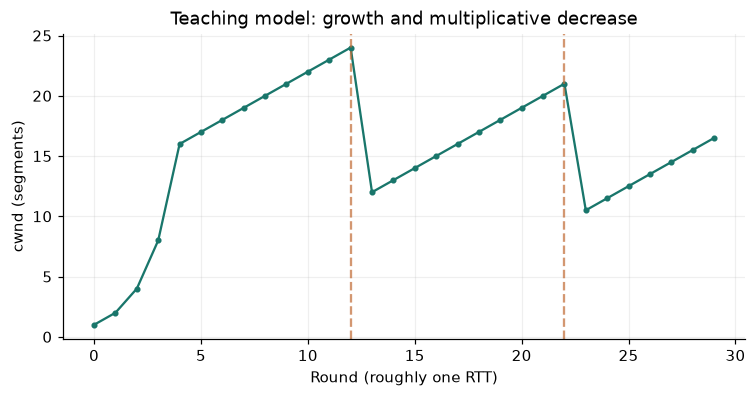

In [20]:
cwnd = 1.0
threshold = 16.0
history = []
loss_rounds = {12, 22}
for round_id in range(30):
    history.append(cwnd)
    if round_id in loss_rounds:
        threshold = max(cwnd / 2, 2)
        cwnd = threshold  # model of multiplicative decrease, not timeout recovery
    elif cwnd < threshold:
        cwnd = min(cwnd * 2, threshold)
    else:
        cwnd += 1
plt.plot(range(30), history, marker=".", color="#19766b")
for r in loss_rounds:
    plt.axvline(r, color="#c16b35", linestyle="--", alpha=0.7)
plt.xlabel("Round (roughly one RTT)")
plt.ylabel("cwnd (segments)")
plt.title("Teaching model: growth and multiplicative decrease")
plt.show()


### 13.2 大缓冲为什么可能更卡

队列能吸收短突发，但持续堆积会增加时延。若出口 10 Mbps，前面有 1 MB 数据等待，仅把队列排空就需约 0.8 秒。这是 **bufferbloat（缓冲膨胀）** 的核心：测速仍可接近满速，但语音和游戏的交互延迟明显变差。

主动队列管理 AQM（例如 CoDel、PIE）和公平排队等机制可以限制持续队列带来的代价。购买更大的缓冲不自动等于更好体验。

对于稳定系统，Little 定律 $L=\lambda W$ 连接平均系统内数量、平均到达率与平均逗留时间；队列持续发散、不存在稳态时不能直接套用稳定平均值。


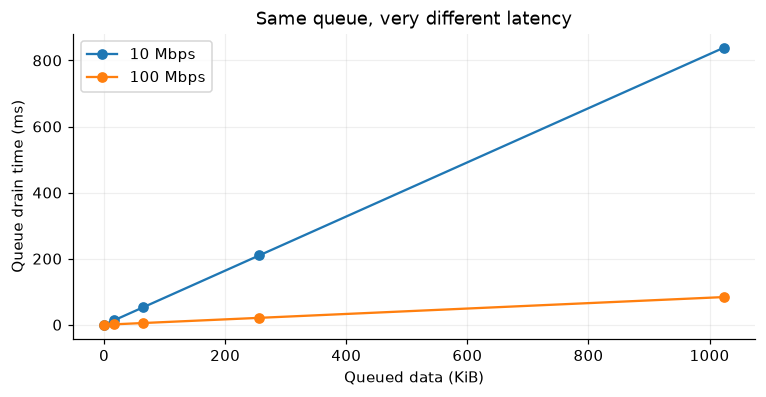

In [21]:
queue_kib = [0, 16, 64, 256, 1024]
for rate_mbps in [10, 100]:
    delays_ms = [q * 1024 * 8 / (rate_mbps * 1e6) * 1000 for q in queue_kib]
    plt.plot(queue_kib, delays_ms, marker="o", label=f"{rate_mbps} Mbps")
plt.xlabel("Queued data (KiB)")
plt.ylabel("Queue drain time (ms)")
plt.title("Same queue, very different latency")
plt.legend()
plt.show()


### 停下来想一想

下载占满宽带时视频通话延迟骤升，但下载速度很好，为什么不矛盾？流控与拥塞控制分别保护谁？

<details>
<summary>展开参考答案（先尝试再看）</summary>

下载吞吐高与队列很长可以同时发生；队列等待使交互流量变慢。流控保护接收端，拥塞控制调节对网络的负载。应观察负载下 RTT，而不是只看带宽测速。

</details>


<a id="ch14"></a>

## 14 · DNS：分布式名称系统与缓存

**这一章学会：** 跟踪递归与迭代；区分记录、TTL、传输和信任。


### 14.1 查询不是“问一台全球大服务器”

浏览器和系统可能先查询自己的缓存，再向递归解析器请求。递归解析器在缓存未命中时，通常从根、顶级域、权威服务器逐级获得指引与答案，然后缓存结果。

- **递归请求：** 客户端希望解析器替自己完成查询。
- **迭代查询：** 服务器返回答案或指向更接近答案的服务器，由查询方继续。
- **权威服务器：** 对某个 DNS 区域提供权威数据。

根服务器通常返回顶级域相关的转介，而不是直接存储所有网站 IP。域名层次中的“域”与管理边界“区域 zone”也不总是同一概念，委派会把管理权分给下级。




后面三者的查询通常由递归解析器发出，不是浏览器分别连接所有服务器。图中箭头表示信息查找顺序，响应逐次返回。


| 类型 | 主要含义 | 示例用途 |
|---|---|---|
| A / AAAA | IPv4 / IPv6 地址 | Web 服务地址 |
| CNAME | 别名指向另一个域名 | 服务别名；通常不能与同名其他常规数据并存 |
| MX | 邮件交换服务器及优先级 | 接收邮件路由 |
| NS | 区域名称服务器 | 委派与权威服务信息 |
| TXT | 文本记录 | SPF 等验证与策略信息 |
| PTR | 反向名称映射 | 从地址查名称，不是正向解析的自动逆函数 |
| SOA | 区域管理信息 | 序列号、负缓存相关参数 |
| HTTPS / SVCB | 服务绑定信息 | 服务端点、协议等发现 |

### 14.2 TTL：缓存有效时间，而不是 IP 包的跳数

DNS TTL 的单位是秒，告诉缓存可保留记录多久。IP TTL 则是逐跳递减的寿命字段，名字相同，语义不同。修改 DNS 后，旧记录在各层缓存中的剩余寿命会影响生效时间；解析器策略和应用缓存也有影响。“全网传播完成”不是一次主动广播事件。

负结果也可以被缓存。`NXDOMAIN` 表示名称不存在，`NOERROR` 但无所查询类型的记录是另一种情况；`SERVFAIL` 通常表示解析过程失败，不能等同于域名不存在。

DNS 常用 UDP 53，也支持 TCP 53；大响应、截断后回退等情况会用到 TCP，EDNS 扩展了能力。DoT 使用 TLS，DoH 使用 HTTPS保护客户端到解析器这一段传输；DNSSEC 验证签名与来源完整性，**不负责加密 DNS 内容**。


In [22]:
# Deterministic TTL model: virtual seconds rather than sleeping.
cache = {}
def cache_put(name, answer, ttl, now):
    cache[name] = (answer, now + ttl)
def cache_get(name, now):
    item = cache.get(name)
    if item is None:
        return None
    answer, expires_at = item
    if now >= expires_at:
        del cache[name]
        return None
    return answer

cache_put("www.example.test", "192.0.2.10", ttl=30, now=100)
assert cache_get("www.example.test", 129) == "192.0.2.10"
assert cache_get("www.example.test", 130) is None
print("t=129: cache hit; t=130: expired, new lookup required")


t=129: cache hit; t=130: expired, new lookup required


In [23]:
# Encode, but do not transmit, one basic DNS A query (no EDNS).
def encode_dns_name(name):
    labels = name.rstrip(".").split(".")
    encoded = []
    for label in labels:
        raw = label.encode("ascii")
        if not 1 <= len(raw) <= 63:
            raise ValueError("Each label must contain 1..63 ASCII bytes")
        encoded.append(bytes([len(raw)]) + raw)
    wire = b"".join(encoded) + b"\x00"
    if len(wire) > 255:
        raise ValueError("Encoded name too long")
    return wire

header = struct.pack("!6H", 0x1234, 0x0100, 1, 0, 0, 0)
question = encode_dns_name("www.example.com") + struct.pack("!HH", 1, 1)
query = header + question
print("DNS query hex:", query.hex(" "))
print("transaction ID, flags, QD, AN, NS, AR:", struct.unpack("!6H", query[:12]))
assert len(query) == 33
assert query[12:16] == b"\x03www"


DNS query hex: 12 34 01 00 00 01 00 00 00 00 00 00 03 77 77 77 07 65 78 61 6d 70 6c 65 03 63 6f 6d 00 00 01 00 01
transaction ID, flags, QD, AN, NS, AR: (4660, 256, 1, 0, 0, 0)


**读十六进制：** 首部共 12 字节，`QDCOUNT=1`；名称不是直接写成带点字符串，而是“标签长度 + 标签字节”，最后用零终止。`QTYPE=1` 代表 A，`QCLASS=1` 代表 IN。真实响应还涉及压缩指针、多个记录与安全校验；这里没有实现通用 DNS 解析器。

**改一改：** 把 QTYPE 改成 28，即 AAAA 查询，比较只有哪些字节发生变化。


### 停下来想一想

改了权威 DNS 的 A 记录，为什么某个用户还连接旧地址？换成 DoH 后是否不再需要信任解析器？

<details>
<summary>展开参考答案（先尝试再看）</summary>

用户或其递归解析器可能仍持有未过期旧记录，应用也可能复用旧连接。DoH 加密到解析器的传输，但解析器仍能处理并看到查询；信任边界发生变化，不会消失。

</details>


<a id="ch15"></a>

## 15 · HTTP：语义、缓存、连接与浏览器

**这一章学会：** 读懂请求响应；比较 HTTP 版本；观察条件缓存。


### 15.1 HTTP 交换的是资源操作语义

HTTP 请求包含方法、目标、字段与可选内容；响应包含状态、字段与可选内容。HTTP/1.1 文本示例：

```http
GET /guide?q=network HTTP/1.1
Host: www.example.com
Accept: text/html

```

实际 HTTP/1.1 行结束是 CRLF，头部结束需要一个空行。HTTP/2 和 HTTP/3 使用二进制帧，不能照搬文本线格式，但共享许多 HTTP 语义。

| 项目 | 关键理解 |
|---|---|
| GET / HEAD | 获取表示 / 获取对应元信息而不传响应内容 |
| POST | 提交处理，默认不能假定幂等 |
| PUT / DELETE | 语义上幂等；重复执行不应产生额外的目标状态效果，响应码可以变化 |
| 200 / 201 / 204 | 成功返回 / 已创建 / 无内容 |
| 301 / 302 / 307 / 308 | 重定向；不同状态的方法保持语义有区别 |
| 304 | 条件请求验证后可复用缓存的表示，没有响应内容 |
| 400 / 401 / 403 / 404 / 429 | 请求问题 / 需认证 / 拒绝访问 / 未找到 / 请求过多 |
| 500 / 502 / 503 / 504 | 服务内部错误 / 网关上游响应错误 / 服务不可用 / 网关等上游超时 |

**安全 safe** 指方法语义不要求修改资源状态；**幂等 idempotent** 指多次相同请求对目标状态的预期效果与一次相同。GET 仍可能产生访问日志；DELETE 第二次返回 404 也不自动失去幂等性。业务 API 必须遵守这些语义，不能只根据方法名猜实现一定正确。

### 15.2 无状态不意味着不能登录

HTTP 无状态指协议请求语义不依赖服务器隐式记住前一次请求。Cookie、令牌、服务器会话等在应用层建立登录状态。Cookie 是浏览器携带状态的机制，不是加密方法；敏感 Cookie 应考虑 Secure、HttpOnly、SameSite 等属性。

浏览器同源由 scheme、host、port 组成。CORS 是浏览器对脚本跨源访问的约束机制，不是服务端身份认证，更不能阻止所有非浏览器客户端发请求。

### 15.3 缓存：有时完全不用发包

新鲜缓存可直接复用；过期后可以发条件请求。服务器给响应附 `ETag`，客户端下次携带 `If-None-Match`，未改变则回 304。

- `Cache-Control: max-age=60`：给出新鲜度期限。
- `no-cache`：允许存储，但复用前需验证；不是“绝不缓存”。
- `no-store`：要求不要存储。
- `private`：针对私有缓存，限制共享缓存保存。
- `Vary`：说明哪些请求字段影响响应选择，防止错误复用不同表示。

### 实验：本机 HTTP 服务与条件请求

第一次 GET 返回正文和 ETag；第二次带 `If-None-Match`，应收到 304；不存在的路径返回 404。这里使用明文回环 HTTP，TLS 在下一章解释。


In [24]:
from http.server import BaseHTTPRequestHandler, HTTPServer
from http.client import HTTPConnection

class LabHandler(BaseHTTPRequestHandler):
    protocol_version = "HTTP/1.1"
    etag = '"network-lab-v1"'
    body = b'{"topic":"computer networks","version":1}'
    def log_message(self, format, *args):
        pass
    def do_GET(self):
        if self.path != "/lesson":
            status, body = 404, b"not found"
        elif self.headers.get("If-None-Match") == self.etag:
            status, body = 304, b""
        else:
            status, body = 200, self.body
        self.send_response(status)
        if self.path == "/lesson":
            self.send_header("ETag", self.etag)
            self.send_header("Cache-Control", "max-age=60")
        if status != 304:
            self.send_header("Content-Type", "application/json" if status == 200 else "text/plain")
            self.send_header("Content-Length", str(len(body)))
        self.send_header("Connection", "close")
        self.end_headers()
        if body:
            self.wfile.write(body)
        self.close_connection = True

@contextmanager
def local_http_server():
    server = HTTPServer(("127.0.0.1", 0), LabHandler)
    thread = threading.Thread(target=server.serve_forever, kwargs={"poll_interval": 0.05},
                              daemon=True)
    thread.start()
    try:
        yield server.server_address
    finally:
        server.shutdown()
        server.server_close()
        thread.join(timeout=3)
        assert not thread.is_alive(), "HTTP thread did not stop"

def http_get(address, path, headers=None):
    conn = HTTPConnection(*address, timeout=3)
    try:
        conn.request("GET", path, headers=headers or {})
        response = conn.getresponse()
        return response.status, dict(response.getheaders()), response.read()
    finally:
        conn.close()

with local_http_server() as address:
    first = http_get(address, "/lesson")
    second = http_get(address, "/lesson", {"If-None-Match": first[1]["ETag"]})
    missing = http_get(address, "/missing")
    print("First:", first[0], first[2].decode())
    print("Conditional:", second[0], "body bytes:", len(second[2]))
    print("Missing:", missing[0])
    assert first[0] == 200 and json.loads(first[2])["version"] == 1
    assert second[0] == 304 and second[2] == b""
    assert missing[0] == 404


First: 200 {"topic":"computer networks","version":1}
Conditional: 304 body bytes: 0
Missing: 404


**模型边界：** 本服务只实现本实验需要的路径、一个固定强 ETag 和精确匹配；不实现完整条件请求语法、Range、认证或生产并发。真实应用应使用成熟服务器与框架。

### 15.4 HTTP/1.1、HTTP/2、HTTP/3 的变化

| 版本 | 关键机制 | 需要理解的限制 |
|---|---|---|
| HTTP/1.1 | 默认支持持久连接；消息常用文本首部，内容长度/分块等方式定界 | 普通串行使用容易等待；流水线也有响应顺序约束，浏览器常开多条连接 |
| HTTP/2 | 二进制分帧、多路复用、HPACK 首部压缩 | 多条流共享 TCP，某段丢失会阻塞后续字节交付，波及多条流 |
| HTTP/3 | 基于 QUIC，多路复用、QPACK | 独立流减少传输层跨流有序交付阻塞；仍共享带宽与拥塞状态，也可能有应用依赖 |

HTTP/2 多路复用解决了 HTTP 层的一些排队限制，却没有消除 TCP 的有序字节流约束。HTTP/3 也不意味着“永不阻塞”或“所有场景都更快”。

浏览器收到 HTML 后，还会请求图片、样式与脚本。网络完成不等于页面可交互；主线程执行、资源依赖、字体加载等也会决定用户体验。


### 停下来想一想

`no-cache` 与 `no-store` 的区别是什么？HTTP/2 在一条 TCP 连接上同时传多个资源，为何仍会受一次丢包影响？

<details>
<summary>展开参考答案（先尝试再看）</summary>

no-cache 允许保存但复用前需要验证；no-store 要求不保存。TCP 交付的是有序字节流，缺失字节前的缺口会阻止其后的字节交付，即使后续字节属于 HTTP/2 的另一条流。

</details>


<a id="ch16"></a>

## 16 · TLS、HTTPS 与 QUIC：安全连接的逻辑

**这一章学会：** 区分加密、完整性与认证；解释证书链和 TLS 1.3 握手。


### 16.1 需要保护三个不同目标

1. **机密性：** 旁观者看不懂内容。
2. **完整性：** 数据被修改时可以检测。
3. **身份认证：** 确认正在与预期身份通信。

对称加密适合高效传输，公钥机制用于身份认证和密钥建立，哈希将任意长度数据映射成固定长度摘要。单独的哈希不证明来源，因为攻击者可以连摘要一起改；HMAC 使用共享密钥认证消息，但它也不加密内容。

现代 TLS 常使用带认证加密 AEAD。TLS 1.3 全握手通常通过临时密钥协商得到会话密钥；在正确实现和密钥处理下提供前向保密，长期认证密钥未来泄漏也不自动暴露过去记录的会话内容。预共享密钥模式等需按具体模式分析。

### 16.2 证书不是“网站绝对可信”的证明

证书将公钥与域名等身份绑定，客户端沿证书链验证到信任根，并检查域名、有效期和相关策略。证书过期、主机名不匹配、根不受信任、系统时间不正确，都可能导致验证失败。

验证成功证明的是连接对端符合受信任体系中的身份条件，不证明网站业务诚实。攻击者也可以为自己的钓鱼域名获得有效证书，所以仍要检查实际访问的域名。

### 16.3 TLS 1.3 全握手的简化路径

```text
客户端                                         服务器
ClientHello（版本、算法、key share、扩展） ------>
                         <------ ServerHello（key share）
                         <------ 加密的握手参数、证书、证明、Finished
验证证书和握手证明，计算并使用会话密钥
Finished ------------------------------------->
加密的应用数据 <===============================> 加密的应用数据
```

这是没有 HelloRetryRequest 等额外情况的概念示意。TLS 1.3 常规全握手通常需要约 1 RTT；若使用 TCP，还要考虑 TCP 建连。恢复连接的 0-RTT 提前数据存在重放风险，不能随意用来执行扣款等不可安全重放操作。

SNI 帮助服务器知道请求哪个域名，ALPN 协商 HTTP/2 等上层协议。常规未使用 ECH 的 ClientHello 中 SNI 可能可见；HTTPS 也不隐藏目的 IP、连接时序和流量大小。路径、查询和正文通常处于加密保护内，但端点、终止 TLS 的代理以及应用日志仍可能看到它们。


In [25]:
import hashlib
import hmac

message = b"amount=100&to=alice"
tampered = b"amount=900&to=alice"
lab_key = b"public-demo-key-not-for-production"
digest = hashlib.sha256(message).hexdigest()
tag = hmac.new(lab_key, message, hashlib.sha256).digest()
print("SHA-256:", digest)
print("HMAC verifies original:", hmac.compare_digest(
    tag, hmac.new(lab_key, message, hashlib.sha256).digest()))
print("HMAC verifies modified:", hmac.compare_digest(
    tag, hmac.new(lab_key, tampered, hashlib.sha256).digest()))
assert hashlib.sha256(message).digest() != hashlib.sha256(tampered).digest()
assert not hmac.compare_digest(tag, hmac.new(lab_key, tampered, hashlib.sha256).digest())


SHA-256: 5dcb6d1ad0b99452f047a475ac313b27b1cc08410a20b8a6b3602ff302278067
HMAC verifies original: True
HMAC verifies modified: False


**读结果：** 修改消息会改变摘要和认证标签。实验密钥公开写在代码里，只用于理解机制；知道它的人可以生成新标签。HMAC 示例不是 TLS 实现，也没有隐藏消息。

### 16.4 QUIC 为什么放在 UDP 上

QUIC 在 UDP 数据报上实现连接、可靠流、拥塞控制、丢失恢复，并集成 TLS 1.3 握手。把传输机制放在用户空间协议中，可以更灵活地演进，不必让网络里的所有设备和操作系统先支持一个新的 IP 传输协议号。

QUIC 的连接 ID 有助于连接在地址或端口变化时继续关联，但迁移仍受验证与策略约束。不同流可独立完成有序交付：一个流丢数据，不必阻止另一条流交付已经完整收到的数据；同一流自己的缺口仍会阻塞它。

**HTTPS 的常见堆栈：** HTTP/1.1 或 HTTP/2 → TLS → TCP → IP；HTTP/3 → QUIC（集成 TLS 安全机制）→ UDP → IP。把 HTTPS 一律写成“HTTP + SSL + TCP”已经不够准确。


### 停下来想一想

证书验证失败后，关闭验证能算修好问题吗？TLS 能防止服务器自己把你的明文写进日志吗？

<details>
<summary>展开参考答案（先尝试再看）</summary>

关闭验证会失去对端身份保障，不是修复；应检查域名、证书链、有效期和系统时间等具体原因。TLS 保护传输链路，不能阻止合法端点在解密后不当处理数据。

</details>


<a id="ch17"></a>

## 17 · 从协议到程序：Socket、超时、重试与服务架构

**这一章学会：** 连接网络机制和操作系统；为真实服务建立失败处理模型。


### 17.1 应用和操作系统在哪里分工

Socket 是程序使用网络栈的接口。典型 TCP 服务端经历 `socket → bind → listen → accept → recv/send → close`；客户端通常 `socket → connect → recv/send → close`。

监听 Socket 与 `accept()` 返回的已连接 Socket 是不同对象。应用写入的数据先进入内核缓冲，再由协议栈安排传输；一次 `send()` 可能只写入部分数据，所以教学代码使用 `sendall()`。阻塞读取等待数据，非阻塞读取可能立即告知当前无数据；事件循环利用就绪通知组织大量连接，但不会自动消除慢 CPU 工作或数据库等待。

文件描述符、内存、临时端口、监听队列和线程数都是有限资源。连接池节省握手成本，也需要限制大小和回收空闲/失效连接。反向代理前后的连接可能完全独立，客户端与代理建立的 TCP 连接不等于代理与应用间的连接。

### 17.2 超时是预算，不是随意填一个整数

一次请求可能包含名称解析、连接、TLS、等待首字节、读取响应等阶段。每阶段超时保护局部等待，**总截止时间 deadline** 控制整次操作。若每一步各等 30 秒，一个本想“最多 30 秒”的请求可能等上几分钟。

- 连接超时：可能是过滤、路由或目标没有回应。
- 连接拒绝：通常表明收到明确拒绝，常见于无监听或主动拒绝策略；不能只据此认定整个主机离线。
- 读取超时：连接已建立，但在期限内没有拿到所需响应。
- 重置：连接被异常终止，需要结合哪一端和何时发生判断。

**业务模糊性：** 客户端超时不证明服务端没执行。支付请求可能已经完成，只是响应丢了。重试需要幂等语义或幂等键及服务端持久化去重，不能指望 TCP 去重替代业务去重。

### 17.3 重试会改变系统负载

指数退避、随机抖动、最大次数和总体预算帮助降低同步重试风暴。只对适合重试的失败执行重试，尊重服务端限流提示；认证失败或参数错误一般应先修正请求。


In [26]:
import random
rng = random.Random(7)
base_s, cap_s, remaining_s = 0.2, 2.0, 3.0
planned_delays = []
for attempt in range(5):
    delay = rng.uniform(0, min(cap_s, base_s * 2**attempt))  # full jitter
    if delay >= remaining_s:
        break
    planned_delays.append(round(delay, 3))
    remaining_s -= delay
print("Illustrative backoff delays (s):", planned_delays)
print("Budget left before accounting for request execution (s):", round(remaining_s, 3))
assert sum(planned_delays) < 3.01


Illustrative backoff delays (s): [0.065, 0.06, 0.521, 0.116, 1.072]
Budget left before accounting for request execution (s): 1.166


上格只生成退避计划，不睡眠、不发请求。真实重试循环还必须扣除每次请求执行的实际时间，并把剩余预算传给连接与读取操作。

### 17.4 常见服务组件

| 组件 | 解决什么 | 不自动解决什么 |
|---|---|---|
| 正向代理 | 代表客户端访问外部服务 | 不保证端到端匿名 |
| 反向代理 | 代表服务接入请求、转发上游 | 不保证上游健康或业务正确 |
| 四层负载均衡 | 按传输连接等信息分配流量 | 通常不理解具体 HTTP 路径 |
| 七层负载均衡 | 按 HTTP 等应用信息分配 | TLS 终止位置与信任边界需要设计 |
| CDN | 边缘缓存与就近接入 | 动态内容和缓存失效仍需策略 |
| 容器网络 | 网络命名空间、虚拟接口、桥接、路由等 | 容器内 localhost 不自动指向宿主机 |
| VPN / 隧道 | 将一段网络流量封装穿过另一网络 | 不修复应用安全，也可能引入 MTU 和路由问题 |

容器里访问 `127.0.0.1`，通常访问的是该容器自己的网络命名空间。服务只绑定回环时，其他机器不能直接连接；改为 `0.0.0.0` 会扩大监听范围，部署时需配合访问控制，而不是随手改成“公开可访问”。


### 停下来想一想

POST 请求超时后，为什么直接重试可能生成两笔订单？只给每次重试设置 3 秒超时，是否保证整体在 3 秒内结束？

<details>
<summary>展开参考答案（先尝试再看）</summary>

超时可能发生在服务端提交之后、响应到达之前；第二次请求可能再次执行。应设计幂等键与服务端去重。每次 3 秒不等于总计 3 秒，必须用统一截止时间扣除请求耗时与退避等待。

</details>


<a id="ch18"></a>

## 18 · 安全：把威胁放回对应层次

**这一章学会：** 识别不同攻击面；区分 NAT、防火墙、TLS 和应用认证。


网络安全不是“用了 HTTPS 就结束”，而是问清：谁可能攻击、能控制哪里、想保护什么、如何验证防护有效。

| 风险 | 可能发生在哪里 | 主要防护思路 |
|---|---|---|
| 无线窃听、未经授权接入 | 接入链路 | WPA2/WPA3、妥善认证、更新设备 |
| ARP 欺骗、伪造 DHCP | 本地二层网络 | 交换侧安全功能、分区、可信接入、监测 |
| DNS 污染或错误解析 | 解析链路与解析器 | 可信解析、加密传输、按需求验证 DNSSEC |
| 中间人读取/修改 | 传输路径 | 正确验证身份的 TLS，保护密钥 |
| 端口暴露与未授权访问 | 网络与服务入口 | 最小开放端口、防火墙、服务认证与授权 |
| 反射放大、连接耗尽 | 网络或协议服务 | 避免开放反射服务、限速、反欺骗、专业防护 |
| 凭据泄露、越权 | 应用及运维 | 凭据保护、最小权限、审计、补丁 |
| 网络侧请求越界 | 服务端发起请求的功能 | 限制目标与解析/重定向、隔离内网、出站策略 |

**防火墙**根据规则允许或拒绝流量；状态防火墙能跟踪连接状态。**TLS**保护传输并认证端点。**应用鉴权**决定某个身份能执行什么操作。它们的职责不同，不能互相替代。

### 实践原则

- 默认只开放业务实际需要的监听地址、端口和来源范围，管理入口与业务入口分开。
- 使用 SSH 等安全远程协议，不把明文 Telnet 当成现代默认方案。
- 日志与抓包按敏感数据管理，分享前移除 Cookie、令牌、内部地址和个人内容。
- 只对自有或获授权环境测试；本书不会要求扫描别人的端口、干扰局域网或关闭系统安全设置。

### 小练习：为“家庭 NAS 远程访问”写威胁模型

列出：需要访问的人、实际服务端口、认证方式、补丁与备份、是否必须公网暴露、设备失窃后的撤销方式。比较直接公网开放和受控 VPN/零信任接入，而不是仅问“怎样做端口映射”。


### 停下来想一想

NAT 后面的设备是不是不需要补丁？把服务端口从 22 改成 22222 是否等价于强认证？

<details>
<summary>展开参考答案（先尝试再看）</summary>

不是。设备仍可能受到内部访问、恶意内容、出站连接关联流量、配置错误等威胁。改端口可以减少部分无差别噪声，不能替代密钥认证、访问控制、补丁和审计。

</details>


<a id="ch19"></a>

## 19 · 观测与排障：从猜测到证据

**这一章学会：** 建立分层检查顺序；读懂时间指标和抓包；记录可验证结论。


### 19.1 先缩小问题，再选择工具

先记录现象：**谁、在什么网络、访问什么地址、什么时候、失败比例、错误文本、是否能稳定复现。** 同一服务在另一网络可用、同一网络其他服务可用，都是有价值的对照。

按依赖关系检查：

```text
链路是否正常？
  -> 地址、掩码、路由是否合理？
    -> 下一跳可达吗？
      -> DNS 返回了什么？
        -> TCP/QUIC 能建立吗？
          -> TLS 验证通过吗？
            -> HTTP 状态与首字节如何？
              -> 应用、数据库、浏览器渲染是否有瓶颈？
```

这是一条起点，不是每次必做的清单。错误已明确指向证书时，先看证书，不必反复测速。保留“观察”和“推断”的区别：`ping` 不回应是观察，“对方主机坏了”只是尚未证实的推断。

### 19.2 只读命令速查（手动选做）

| 要看什么 | macOS | Linux | Windows PowerShell / 命令行 |
|---|---|---|---|
| 地址与接口 | `ifconfig` | `ip addr` | `ipconfig /all` |
| 默认路由 | `route -n get default` | `ip route` | `route print` |
| 邻居缓存 | `arp -an` | `ip neigh` | `arp -a` |
| 名称解析 | `dig example.com A` | `dig example.com A` | `Resolve-DnsName example.com` |
| 有限次 ICMP 探测 | `ping -c 4 example.com` | `ping -c 4 example.com` | `ping -n 4 example.com` |
| 路径探测 | `traceroute example.com` | `tracepath example.com` | `tracert example.com` |
| 监听端口 | `lsof -nP -iTCP -sTCP:LISTEN` | `ss -lntup` | `Get-NetTCPConnection -State Listen` |

这些工具的安装情况、权限和输出格式取决于系统。表中域名是演示目标；实际排障替换为你有权访问的服务，避免高频或大规模探测。普通外部访问可能暴露你的公网 IP 和查询内容。

### 19.3 用 curl 分解时间

在终端手动运行（Windows 可用 `curl.exe`，换行写法需按终端调整）：

```bash
curl --max-time 10 -o /dev/null -sS \
  -w 'dns=%{time_namelookup} connect=%{time_connect} tls=%{time_appconnect} ttfb=%{time_starttransfer} total=%{time_total}\n' \
  https://example.com/
```

这些值通常是**从操作开始累计**的时间，不是可以直接相加的独立阶段耗时。对一次无代理、无重定向、新建 TCP/TLS 连接的简单请求，可以用相邻时间差近似拆分；连接复用、代理、多地址尝试等会改变含义。`time_starttransfer` 包含此前步骤，不等于纯服务器处理时间。

不要用 `-k` 跳过证书验证来宣布 HTTPS 故障已修复。若要绕过 DNS 进行对照，应保留原主机名的 Host/SNI，例如用 `--resolve` 指定你已核实的服务地址；直接把 HTTPS 域名换成 IP 可能制造新的证书错误。


DNS: 12 ms
TCP after DNS: 30 ms
TLS after TCP: 38 ms
Request + wait for first byte: 150 ms
Body transfer: 200 ms


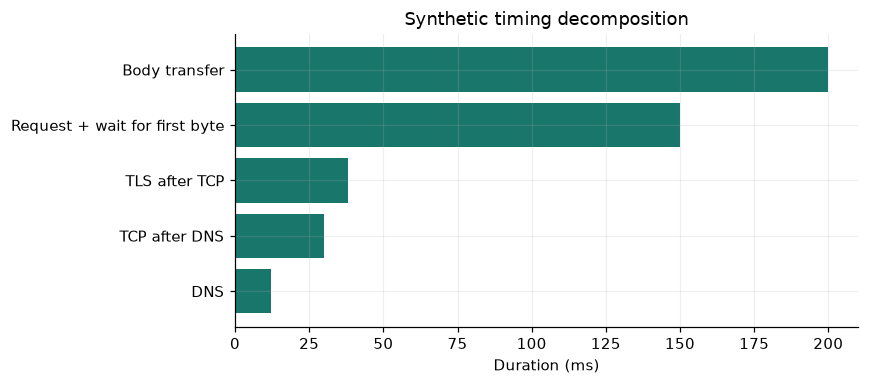

In [27]:
# Synthetic curl-like cumulative timings, not a measurement of the internet.
cumulative = {"dns": 0.012, "connect": 0.042, "tls": 0.080,
              "ttfb": 0.230, "total": 0.430}
phases = {
    "DNS": cumulative["dns"],
    "TCP after DNS": cumulative["connect"] - cumulative["dns"],
    "TLS after TCP": cumulative["tls"] - cumulative["connect"],
    "Request + wait for first byte": cumulative["ttfb"] - cumulative["tls"],
    "Body transfer": cumulative["total"] - cumulative["ttfb"],
}
for name, seconds in phases.items():
    print(f"{name}: {seconds * 1000:.0f} ms")
assert math.isclose(sum(phases.values()), cumulative["total"])
plt.barh(list(phases), [v * 1000 for v in phases.values()], color="#19766b")
plt.xlabel("Duration (ms)")
plt.title("Synthetic timing decomposition")
plt.tight_layout()
plt.show()


### 19.4 Wireshark：抓包前先写假设

在自己的本机回环接口上捕获第 11 或第 15 章实验，能够观察真实 TCP 报文与明文 HTTP。macOS 常用 `lo0`，Linux 常用 `lo`，Windows 的回环捕获依赖相应捕获支持。抓包通常需要额外捕获权限，本书不会自动安装驱动或修改权限。

1. 选对接口，只捕获短时间，运行一个实验后停止。
2. 找到本次连接的临时端口，用 `tcp.port == 端口号` 缩小范围。
3. 观察 SYN、SYN/ACK、ACK；再看相对序号、ACK、负载长度和关闭。
4. 用 “Follow TCP Stream” 重组应用字节；重组结果与单个包是不同视图。
5. 回答你的假设：是否成功建立连接？是否发送请求？是否有响应？是否重传？

| Wireshark 显示过滤器 | 用途 |
|---|---|
| `dns` | 传统 DNS 解析流量，DoH/DoT 不会都以可读 DNS 出现 |
| `arp` | 查看 IPv4 邻居解析 |
| `icmp || icmpv6` | 网络诊断与控制报文 |
| `tcp.flags.syn == 1` | 找握手起点 |
| `tcp.analysis.retransmission` | 查看分析器判断的重传线索 |
| `tcp.stream eq 0` | 查看编号为 0 的 TCP 流，编号按当前捕获而定 |
| `http` | 查看被识别的明文 HTTP，不会自动解密 HTTPS |

**捕获过滤器**与**显示过滤器**语法不同：前者可写 `tcp port 8080`，后者写 `tcp.port == 8080`，不能原样互换。临时高端口上的 HTTP 如未自动识别，可用 Decode As；HTTPS 解密需要合法获得的会话密钥等支持，不是勾选一个普通过滤器就能实现。

**主机抓包的三个陷阱：** 校验和卸载可能导致看到尚未填好校验和的出站包；TSO/GSO 等卸载可能让捕获尺寸不同于最终线上分段；抓包自身丢包可能被误判为网络丢包。分析器标签是线索，不是最终定论。

### 19.5 五个小案例

| 现象 | 优先假设 | 下一项证据 | 不能直接推出 |
|---|---|---|---|
| 域名失败，保留 Host/SNI 指定已知地址后成功 | DNS 路径或答案问题 | 解析错误、返回地址、不同解析位置的对照 | 所有网络层都完全正常 |
| TCP 立即被拒绝 | 无监听或主动拒绝 | 服务监听、目标地址/端口、防火墙日志 | 整台主机离线 |
| TCP 成功，TLS 主机名不匹配 | 证书/SNI/服务入口配置错误 | 请求域名、证书 SAN、代理配置 | 应该关闭校验 |
| 小请求通，大响应卡住 | MTU/反馈、丢包或应用发送问题 | 包长、重传、ICMP、VPN 对照 | 一定是带宽不足 |
| HTTP 502/504 | 网关与上游链路或服务异常 | 代理日志、上游时延、连接错误 | 客户端 DNS 必然失败 |

**排障记录模板：** 现象 → 影响范围 → 当前假设 → 最小验证动作 → 观察结果 → 假设是否保留 → 下一步。避免一次改 DNS、关 VPN、换网卡、重启服务，因为即使恢复也无法知道哪个变量起作用。


### 停下来想一想

curl 的 connect=0.050、tls=0.090、ttfb=0.300，能说服务器处理用了 300 ms 吗？抓包显示出站 TCP 校验和错误，是否一定有线上损坏？

<details>
<summary>展开参考答案（先尝试再看）</summary>

不能，TTFB 是累计时间；简单新连接情形下，TLS 之后至首字节约 210 ms，仍包含请求传输、网络等待和服务处理。主机出站校验和可能稍后由网卡补齐，需检查卸载与捕获位置，不能仅凭标签判定线上损坏。

</details>


<a id="ch20"></a>

## 20 · 综合项目：画出一次访问，写出一份诊断报告

**这一章学会：** 把各层知识串成可验证的解释；用综合题检查掌握程度。


### 项目 A · 完整复述一个 HTTPS 请求

场景：笔记本 `192.168.10.34/27`，网关 `192.168.10.33`，递归 DNS 也由网关提供；网站解析到 `203.0.113.80`；家庭网络有 NAT。所有缓存为空，使用 HTTPS over TCP，忽略代理和 VPN。

请画一页图并标出：

1. 本机所属子网、广播地址、网关是否在同一子网。
2. DNS 解析由谁发起、可能查询哪些角色，ARP 查询的对象是谁。
3. 发往网站的首个本地帧中，目的 IP 与目的 MAC 分别属于谁。
4. NAT 可能修改哪些字段，路由器沿途更新什么。
5. TCP 握手、TLS 身份验证、HTTP 请求的先后关系。
6. 网站返回 200 后，为什么页面仍可能继续等待。

**验收：** 能在图上分别追踪名称、IP、MAC、端口、TCP 字节、HTTP 消息；能说明哪些值逐跳变化、哪些在普通路由中不变。

<details>
<summary>项目 A 参考路线</summary>

本机位于 192.168.10.32/27，广播 .63，可用 .33–.62，网关 .33 在本地网段。主机先通过 ARP 获取网关 MAC，以便向作为 DNS 服务的网关发送查询；递归查询可能访问根、TLD、权威服务器。得到网站 IP 后，查路由选默认网关，网站 IP 仍是包的目的地址，本地帧目的 MAC 是网关。

NAT 可能改写源 IP、源端口并更新相关校验信息；各路由器减少 TTL、为出口链路重建帧。普通中转路由不改变网站目的 IP。TCP 握手后进行 TLS 认证与密钥建立，再加密交换 HTTP。HTML 触发的资源、JavaScript 执行、渲染和应用数据请求都可能延迟可交互时刻。

</details>

### 项目 B · 给本机 HTTP 实验做一次诊断

复用第 15 章代码，完成三项互相独立的观察：

- `/lesson` 首次返回 200；使用正确 ETag 返回 304；错误 ETag 应重新返回 200。
- `/missing` 返回 404，说明网络和 HTTP 服务已到达，但资源不存在。
- 把 ETag 和内容版本一起改为 v2，旧 ETag 应得到新正文，而不是 304。

为每项写下“预期、观察、解释”。可选：抓取自己的回环 HTTP 流，指出状态行与 ETag；不做抓包也能完成主项目。

### 项目 C · 写一份“下载快但会议卡”的报告

允许提出的最小观测：空闲时 RTT、下载期间 RTT、丢包/重传、同一局域网有线与无线对照。先提出排队或无线干扰假设，再解释每项证据如何支持/否定它。不要只给出“升级带宽”这一结论。


In [28]:
# Project B: compare the validator behavior without modifying system settings.
with local_http_server() as address:
    mismatched = http_get(address, "/lesson", {"If-None-Match": '"old-version"'})
    assert mismatched[0] == 200 and mismatched[2]
    old_etag, old_body = LabHandler.etag, LabHandler.body
    try:
        LabHandler.etag = '"network-lab-v2"'
        LabHandler.body = b'{"topic":"computer networks","version":2}'
        updated = http_get(address, "/lesson", {"If-None-Match": old_etag})
        assert updated[0] == 200
        assert json.loads(updated[2])["version"] == 2
        assert updated[1]["ETag"] == '"network-lab-v2"'
    finally:
        LabHandler.etag, LabHandler.body = old_etag, old_body
print("Validator mismatch returns 200; changed validator invalidates the old cache token")
print("Old ETag retrieves the updated representation, version:", json.loads(updated[2])["version"])


Validator mismatch returns 200; changed validator invalidates the old cache token
Old ETag retrieves the updated representation, version: 2


### 综合自测（建议闭卷）

1. `/28` 普通 IPv4 子网有多少地址、多少常规可用主机地址？
2. 本机访问异网段目标时，是 ARP 目标服务器还是 ARP 下一跳？
3. 1500 字节包在 10 Mbps 链路上的发送时延是多少？
4. 200 Mbps、RTT 40 ms 的 BDP 是多少字节？
5. TCP 已按序收到 5000–5999，接下来 7000–7999 到达，累计 ACK 应如何变化？
6. TCP 与 UDP 在消息边界方面有何不同？
7. 接收窗口与拥塞窗口为什么不能合成同一个概念？
8. DNS NXDOMAIN、SERVFAIL、超时分别表达什么？
9. HTTPS 已成功握手，HTTP 返回 403，该优先检查什么？
10. HTTP/3 为什么既基于 UDP，又可以可靠传输？
11. 连接成功但大响应卡住，列出两项应采集的证据。
12. 请求超时后安全重试一个创建订单接口，需要什么业务机制？

<details>
<summary>综合自测答案</summary>

1. 共 16 个地址，通常 14 个可用主机地址。
2. 查路由后解析本地下一跳地址；普通异网段访问通常是网关。
3. 1500×8/10⁷=0.0012 秒，即 1.2 ms。
4. 200×10⁶×0.04/8=1,000,000 字节。
5. 若此前连续前缀已到 5999，ACK 为 6000；7000–7999 乱序到达仍为 6000，直到缺口补齐。
6. TCP 是字节流，不保留应用写入边界；UDP 是数据报，保留消息边界，但不内建可靠交付。
7. 一个反映接收方缓冲能力，一个反映网络拥塞约束；接收快不代表路径不堵。
8. 名称不存在、解析服务处理失败、在期限内未获得响应；三者不是同一故障。
9. 应用鉴权、授权、访问策略及网关规则，而不是先重做物理连线测试。
10. 可靠流、丢失恢复和拥塞控制由 QUIC 实现，UDP 是承载层。
11. 包长与重传模式、ICMP Packet Too Big/需要分片反馈、路径 MTU/VPN 对照、服务端发送日志等。
12. 稳定幂等键、服务端持久化去重和结果查询，配合总超时预算、退避与重试边界。

</details>

### 四周复习节奏

- **第 1 周：** 00–07，每天练一次子网题，画出同网段与跨网段发包差别。
- **第 2 周：** 08–13，用手画路由选择、握手、ACK 和窗口变化，再对照代码。
- **第 3 周：** 14–18，运行本机 DNS 编码、HTTP 缓存与 TCP 分帧实验，解释安全边界。
- **第 4 周：** 19–21，完成项目 A/B/C，整理自己答错的自测题。

**达到入门目标的标志：** 你能解释每个实验的预期结果，修改一个参数后能预测方向，面对故障能提出可验证的下一步。继续深入时再研究更完整的协议实现和真实网络测量。


<a id="ch21"></a>

## 21 · 回看协议全景图：勘误、速查与延伸阅读

**这一章学会：** 把旧图变成学习索引，而不是把每个框都当成必背内容。


<details>
<summary>展开你提供的协议全景图（历史资料，对照下表阅读）</summary>

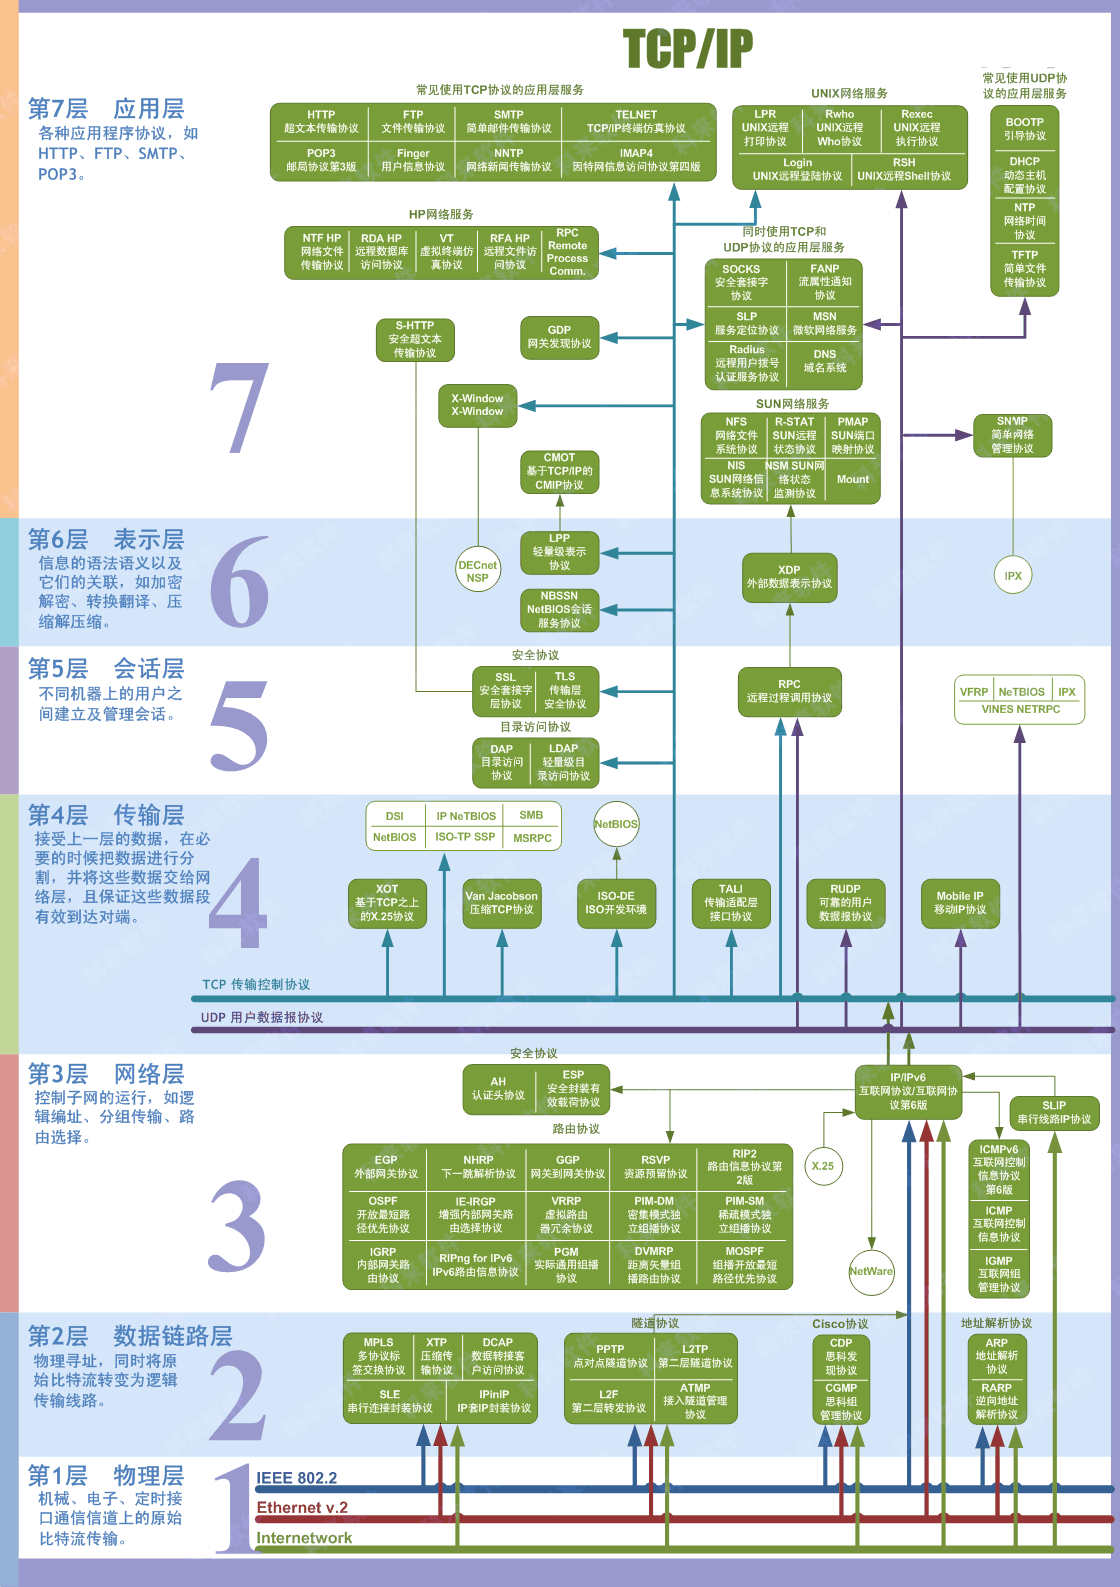

</details>

原图作为对照资料内嵌保存，离线也可阅读；技术分层与现代用法以本书正文和下表说明为准。


### 21.1 你提供的图应该怎样读

| 图中的表达或容易形成的印象 | 现代学习时的处理 |
|---|---|
| “TCP/IP”标题下画 OSI 七层 | 两套模型相关但不相同，按第 2 章映射理解 |
| 把 Ethernet、IEEE 802.2 等都放在最底部附近 | 以太网涉及物理与链路层；802.2 是逻辑链路控制，不是单纯物理层协议 |
| SSL/TLS 被固定放在会话层 | TLS 通常在应用与传输之间提供安全机制，不能机械固定在 OSI 某一层 |
| IPX 在表示层附近出现，Mobile IP 靠近传输层 | IPX 是历史网络层协议族中的网络层协议；Mobile IP 属网络层移动性机制，图的几何位置不可直接当严格分层 |
| DNS 只需区分“同时用 TCP/UDP” | 还要学习缓存、递归/权威、DoT/DoH 和 DNSSEC 的不同职责 |
| TCP 的连线代表“应用必须永远用 TCP” | HTTP/3 使用 QUIC/UDP，应用与传输的组合会演进 |
| S-HTTP、SSL 等看起来都像现代 HTTPS | S-HTTP 是历史协议，与今天普遍的 HTTPS 不同；SSL 已过时，应学习现代 TLS |
| Telnet、RSH、Rexec 与 SSH 同等推荐 | 前者多为历史/遗留场景，现代远程管理优先理解 SSH 与身份控制 |
| RARP、BOOTP、IPX、NetWare 等占据大量版面 | 认识演进背景即可，初学优先掌握 DHCP、IPv4/IPv6、TCP/UDP、DNS、HTTP/TLS |
| 箭头多，仿佛是一次真实数据流 | 它更像关联索引；真实路径要结合封装、端点、设备角色与运行状态分析 |

图中的 FTP、SMTP、POP3、IMAP、SNMP、NTP、LDAP、NFS、RPC 等仍有学习价值，但重要程度取决于应用场景：

- **文件与邮件：** FTP 的控制/数据连接不同；SFTP 运行在 SSH 上，不是“给 FTP 加 TLS”（后者通常称 FTPS）。SMTP 负责邮件传输，IMAP/POP3 负责邮箱访问。
- **运维：** NTP 同步时钟，时钟错误会影响证书、日志与分布式系统；SNMP 用于管理监测，应理解不同版本的安全差异。
- **身份与存储：** LDAP 提供目录访问；NFS 提供网络文件系统；RPC 是远程过程调用范式及相关协议的总称，底层承载依实现而异。
- **网络控制：** OSPF/BGP 是路由学习主线；VRRP 是网关冗余机制，不等于寻找互联网最短路径的路由协议；IGMP 用于 IPv4 多播成员管理，IPv6 对应机制是 MLD。

### 21.2 术语回看

| 术语 | 一句话记忆 |
|---|---|
| Frame / Packet / Segment / Datagram | 帧 / 包 / TCP 段 / 数据报；“packet”在日常语境也会泛指分组 |
| MAC / IP / Port | 当前链路地址 / 跨网络地址 / 传输端点分流标识 |
| MTU / MSS | 链路承载 IP 包的上限 / TCP 段中数据大小上限 |
| RTT / BDP | 往返时延 / 为充分利用路径所需的在途数据量级 |
| TTL | IP 中是逐跳寿命；DNS 中是缓存秒数 |
| Flow control / Congestion control | 保护接收者 / 调节网络负载 |
| NAT / Firewall / Proxy | 地址转换 / 访问过滤 / 代表一端建立或处理通信 |
| TLS / Certificate / CA | 安全协议 / 身份与公钥绑定 / 证书签发与信任体系角色 |
| Latency / Jitter / Loss | 延迟 / 延迟变化 / 丢失 |
| Unicast / Broadcast / Multicast / Anycast | 单播 / 广播 / 多播 / 多点宣告同地址并由路由选取一个到达点 |

Anycast 常见于 DNS/CDN 等设施。它依赖路由选出一个实例，不保证地理上最近或处理负载最低。

### 21.3 一页计算卡

```text
bit = byte × 8
发送时延 = 数据比特数 / 链路 bit/s
传播时延 = 距离 / 信号速度
BDP（字节）= 带宽 bit/s × RTT 秒 / 8
窗口约束吞吐上限 = 窗口比特数 / RTT 秒
普通 IPv4 /p 子网地址总数 = 2^(32-p)
普通 IPv4 /p 可用主机数 = 2^(32-p)-2（/31、/32 等需单独处理）
常见 TCP 数据上限估算 = 路径 MTU - IP 首部 - TCP 首部
队列排空时间 = 队列比特数 / 出口 bit/s
```

使用公式前写下单位、前提、测量层次。字节与比特、累计时间与阶段时间、理论上限与实测结果，是最常见的三类错误。

### 21.4 延伸阅读：先读机制，再读规范

**教材路线：** Kurose & Ross《计算机网络：自顶向下方法》适合从应用建立直觉；Tanenbaum 等《计算机网络》提供更完整体系；Stevens《TCP/IP 详解》适合配合抓包，但旧版案例需结合现代规范理解。

**可免费访问的标准与工具资料：** 以下链接用于深入核对各章机制，不要求从头通读 RFC。RFC 可能有勘误、更新或后续扩展，阅读时查看页面的状态与更新关系。

| 主题 | 资料 | 建议先看什么 |
|---|---|---|
| IPv4 | [RFC 791](https://www.rfc-editor.org/rfc/rfc791) | 基本首部、寻址与分片 |
| 私网与 CIDR | [RFC 1918](https://www.rfc-editor.org/rfc/rfc1918)、[RFC 4632](https://www.rfc-editor.org/rfc/rfc4632) | 私有地址范围、前缀路由 |
| /31 点到点 | [RFC 3021](https://www.rfc-editor.org/rfc/rfc3021) | 为什么 /31 不按常规减二 |
| ARP / DHCPv4 | [RFC 826](https://www.rfc-editor.org/rfc/rfc826)、[RFC 2131](https://www.rfc-editor.org/rfc/rfc2131) | 邻居映射与租约流程 |
| IPv6 / NDP | [RFC 8200](https://www.rfc-editor.org/rfc/rfc8200)、[RFC 4861](https://www.rfc-editor.org/rfc/rfc4861) | 首部、路由器与邻居发现 |
| IPv6 地址自动配置 | [RFC 4862](https://www.rfc-editor.org/rfc/rfc4862) | SLAAC、重复地址检测 |
| UDP / TCP | [RFC 768](https://www.rfc-editor.org/rfc/rfc768)、[RFC 9293](https://www.rfc-editor.org/rfc/rfc9293) | 服务模型、首部、状态机 |
| TCP 拥塞与定时器 | [RFC 5681](https://www.rfc-editor.org/rfc/rfc5681)、[RFC 6298](https://www.rfc-editor.org/rfc/rfc6298) | 经典算法与 RTO 计算 |
| DNS | [RFC 1034](https://www.rfc-editor.org/rfc/rfc1034)、[RFC 1035](https://www.rfc-editor.org/rfc/rfc1035) | 名称体系、消息格式 |
| DoH / DNSSEC | [RFC 8484](https://www.rfc-editor.org/rfc/rfc8484)、[RFC 4033](https://www.rfc-editor.org/rfc/rfc4033) | 传输加密与数据认证的不同目标 |
| HTTP 语义与缓存 | [RFC 9110](https://www.rfc-editor.org/rfc/rfc9110)、[RFC 9111](https://www.rfc-editor.org/rfc/rfc9111) | 方法、状态、验证器与缓存 |
| HTTP/1.1、2、3 | [RFC 9112](https://www.rfc-editor.org/rfc/rfc9112)、[RFC 9113](https://www.rfc-editor.org/rfc/rfc9113)、[RFC 9114](https://www.rfc-editor.org/rfc/rfc9114) | 不同版本的消息承载 |
| TLS 1.3 / QUIC | [RFC 8446](https://www.rfc-editor.org/rfc/rfc8446)、[RFC 9000](https://www.rfc-editor.org/rfc/rfc9000)、[RFC 9001](https://www.rfc-editor.org/rfc/rfc9001) | 安全握手、流、TLS 与 QUIC 集成 |
| Python Socket | [Python socket 文档](https://docs.python.org/3/library/socket.html) | recv、sendall、超时与关闭 |
| 抓包 | [Wireshark User’s Guide](https://www.wireshark.org/docs/wsug_html_chunked/) | 捕获接口、显示过滤、流重组 |
| 请求观测 | [curl 手册](https://curl.se/docs/manpage.html) | write-out、超时、resolve |

### 下一步可以选的方向

- **系统方向：** 阅读 TCP 状态机，研究 epoll/kqueue、内核缓冲和高并发服务器。
- **网络工程：** 在隔离模拟环境中配置 VLAN、静态路由、OSPF/BGP，观察故障收敛。
- **Web 工程：** 研究 HTTP 缓存、CDN、反向代理、连接复用和可观测性。
- **分布式系统：** 从网络延迟与部分失败出发，学习一致性、复制、幂等与故障恢复。

回到[学习路线](#ch00)，重做你解释不清的那一格，比继续背更多缩写更有效。
